<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/SQLearn_PCA_IntrusionDetection_Bellante2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulated quantum PCA for intrusion detection (fault-tolerant regime): Bellante et al. (2025) step by step

This notebook re-implements, runs and checks the case study of

> Armando Bellante, Tommaso Fioravanti, Michele Carminati, Stefano Zanero and Alessandro Luongo,
> "Evaluating the Potential of Quantum Machine Learning in Cybersecurity: A Case-Study on PCA-based Intrusion Detection Systems",
> *Computers & Security* (2025), article 104341. DOI 10.1016/j.cose.2025.104341, arXiv:2502.11173.

**What kind of paper is this?** It is *not* a near-term (NISQ) circuit paper. It asks a resource question about *future, error-corrected*
quantum computers: if quantum PCA (QPCA, Bellante et al. 2022) were available, would it train PCA-based intrusion detectors faster than a
classical computer, and how much of the quantum algorithm's *approximation error* can a detector tolerate? The authors answer it with a
four-step methodology: (1) simulate the quantum subroutines on a classical machine by injecting the errors the theorems allow
(phase-estimation error `eps` on singular values, threshold-search error `eta`, tomography error `delta` on singular vectors),
(2) measure the dataset quantities that appear in the quantum running-time theorems (norms, `mu(X)`, thresholds, number of components),
(3) plot quantum versus classical query counts as the data grow and read off where they cross, and (4) estimate the physical cost of the memory (QRAM) the algorithm needs.

**What this notebook does.** It downloads KDD Cup 99 (10 %), CIC-IDS2017 and CIC-MalMem-2022, rebuilds the paper's three detectors
(Principal Component Classifier, Ensemble PCC, PCA reconstruction loss) with classical PCA, re-implements the quantum error models and
re-draws the paper's Tables 3, C.7, 4 and 5, then measures the parameters of the running-time theorems on the real data and re-draws the
running-time comparison of Figure 4, the tomography study of Appendix C, the clustering check of Appendix E and the QRAM arithmetic of Section 5.8.
It ends with a claim-by-claim comparison with the paper. **No quantum circuit is executed** (the paper gives none), so the circuit section is `NOT_APPLICABLE`.

**How to run it.** Open in Google Colab, CPU runtime, *Runtime > Run all*. `FAST_MODE = True` (default) finishes in a few minutes
(the CIC-IDS2017 download and parsing, about 3 minutes, dominates); `FAST_MODE = False` repeats the simulated-quantum draws more often
(10 instead of 3) and the tomography experiment 1000 instead of 200 times, as in the paper. No GPU, no quantum SDK and no IBM token are needed.

**What you get at the end.** Re-drawn tables with the paper's value next to ours, measured running-time parameters, a figure of the
classical-versus-quantum cost curves with the crossover sample sizes, and a verdict per claim.

## The paper in one page

**Problem.** Network intrusion detection as *anomaly detection*: fit a PCA model on **normal traffic only**, flag everything that does not fit.

**Detectors (Section 5.1, Figure 2).**
* *PCC* (Shyu et al.): with the standardized sample `z`, principal components `e_i` and eigenvalues `lambda_i`, compute `T1 = sum_{i<=k} (e_i.z)^2 / lambda_i` over the
  top-`k` ("major") components and `T2` over the `q` least ("minor") ones; flag an attack if `T1 > c1` or `T2 > c2`. The thresholds come from the false-alarm rate `alpha`.
* *Ensemble PCC* (the authors' extension): the same sums with three kinds of `y_i`: the dot product, the cosine similarity and the correlation coefficient between `e_i` and `z`; six sums, any one above its threshold flags an attack.
* *Reconstruction loss*: project `z` on the top-`k` components and back, the sum of squared errors is the anomaly score, compared with a threshold `t`.

**Quantum part (Section 5.1, Appendix B).** QPCA = quantum binary search for the singular-value threshold `theta` (Theorem B.8, parameters `p`, `eta`, `eps_theta`)
followed by top-`k` (or least-`q`) singular-vector extraction by phase estimation plus pure-state tomography (Theorem B.9, parameters `eps`, `delta`).
Running times: binary search `O~(mu/(eps*eta) * log(mu/eps))`, top-`k` extraction `O~(d*k*||X||*mu(X)*log(k)*log(d) / (theta*sqrt(p)*eps*delta^2))`,
least-`q` extraction `O~(theta_min/sigma_min * mu/eps * q*d/sqrt(p_min))`; classical references: randomized PCA `O(n*d*k*log k)` and full SVD `O(n*d^2)`.

**Data (Section 5.2).** KDDCUP99 (5 000 normal training samples, 92 278 normal + 39 674 attack test samples), CIC-IDS2017 DDoS-vs-normal (5 000 training, 87 300 normal + 70 000 DDoS test),
CIC-IDS2017 all attacks (50 000 training, 60 000 + 166 966 validation, 140 000 + 389 590 test), DARKNET (85 features), and CIC-MalMem-2022 for the tomography study.

**Claims to check.** (i) with `eps=1, eta=0.1, delta=0.1` the quantum detectors match the classical ones (Tables 3, C.7, 4, 5, 6); (ii) the Ensemble PCC clearly beats PCC on CIC-IDS2017 (Table 4);
(iii) a larger `delta` makes the model flag more points as attacks (Tables 5, 6); (iv) a quantum query-count advantage appears only for very large data (about 4e6 samples x 50 features for PCC-major on KDD,
about 2e9 samples for CIC-IDS2017, none for minor components with full SVD at 3e7 x 500); (v) tomography needs about 1e4 measurements instead of the 1e7 of the bound (Appendix C);
(vi) one QRAM query for 1e7 x 44 data would need 1.37e11 logical qubits (Section 5.8).

### What follows the paper and what had to be chosen

The paper's simulation code (`sq-learn`) is described but not reproduced in the article, and several details are not given. Every item below marked **CHOICE** is also tagged `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Phase-estimation error on singular values | `\|sigma_est - sigma\| <= eps`, "consistent" (same error on repeated runs) | one fixed vector `u ~ U(-1,1)^d` per simulated device, `sigma_est = \|sigma + eps*u\|` (**CHOICE**, pessimistic uniform error that uses the full `eps`) |
| Binary search for `theta` | Theorem B.8: returns `theta` whose kept variance is within `eta` of `p` | real bisection on `[0, sigma_est_max]`; each probe compares `p` with the kept variance plus an amplitude-estimation error `U(-eta, eta)` (**CHOICE**) |
| Tomography of singular vectors | `N = 36*d*ln(d)/delta^2` measurements, error `delta`; heuristic: `N/100` | `measure`: draw `N` multinomial samples from the true `e_i^2`, signs known (as in sq-learn's `L2_tomogrphy_fakeSign`); `noise`: `e_i + delta*u`, `\|u\|=1`, re-normalised (pessimistic, error exactly `delta`; the only way to reach `delta` > 1.4 as in Tables 5 and 6) |
| Unit of `eps`, `theta` | not stated | singular values of the *unscaled* training matrix `X` (n rows), so `eps = 1` on 5 000 samples is a small relative error |
| Minor components (Shyu) | `theta_min = sqrt(0.20)` | components whose covariance eigenvalue `sigma^2/n < 0.20`, i.e. `theta_min = sqrt(0.20*n)` in `X` units (**CHOICE**) |
| KDD training set | 5 000 normal samples "by trimming and systematic random sampling" | systematic sample (random start) of 5 000 normal rows, then the 1 % with the largest Mahalanobis distance removed (**CHOICE**) |
| KDD data | KDDCUP99 numerical features | the official 10 % file (494 021 rows, 38 numerical features, constant ones dropped); the paper's test sizes 92 278 / 39 674 equal "all other normal rows" and "10 % of the attack rows" |
| Threshold `c` from `alpha` | "computed on a validation set" | the `(1-alpha)` quantile of the scores of the **untrimmed** 5 000-sample the training set was trimmed from, which still contains the outliers (**CHOICE**; no separate validation set is mentioned for Tables 3 and 4 and the test set uses all other normal rows) |
| CIC-IDS2017 DDoS test set | 87 300 normal + 70 000 DDoS | same sizes, drawn at random from the Friday-afternoon DDoS file (97 686 benign, 128 025 DDoS after cleaning) |
| CIC-IDS2017 all-attack split | 50 000 / (60 000 + 166 966) / (140 000 + 389 590) | same sizes: after dropping NaN/inf rows the 8-file collection has exactly 556 556 attack rows = 166 966 + 389 590; benign rows are drawn at random |
| Reconstruction-loss preprocessing | "quantile transform", 751 quantiles | `QuantileTransformer(n_quantiles=751, output_distribution="uniform")` fitted on the training split, no further scaling (**CHOICE**; the paper's `t = 0.425` is on the scale of unscaled uniform features) |
| Reconstruction-loss `k` and `t` | 12 components (94.88 % of the variance), `t = 0.425` | `k` and `t` chosen by validation F1 over a grid (`RL_K_GRID`); the paper's `k = 12` is also evaluated |
| Test-set composition of Table 5 | 140 000 normal + 389 590 attack | used as stated, **and** the metrics re-weighted to the attack share (about 18.6 %) that the paper's own Table 5 numbers imply (see section 8) |
| DARKNET (Table 6, Figure 5) | CIC-Darknet2020 | **not publicly downloadable without a form** (no Hugging Face mirror, UNB links return a web page): reported as BLOCKED, not substituted |
| Running-time scaling in `n` and `d` | "vary n and d" | measured parameters kept fixed in *relative* units (`mu/eps`, `\|X\|/theta`, `k`), explicit `d` factor of the theorems kept; logs are `log2`; hidden constants of `O~` set to 1 (**CHOICE**) |
| Classical baseline | PCA with scikit-learn | identical pipeline with exact `numpy.linalg.svd`; plus a *supervised* reference (Random Forest, RBF-SVC on the same PCA features) |

In [1]:
# ---- install (Colab only; nothing quantum is needed: the paper's quantum parts are simulated with numpy) ----
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _missing(mods):
    out = []
    for m in mods:
        try: importlib.import_module(m)
        except Exception: out.append(m)
    return out
if IN_COLAB or _missing(["huggingface_hub", "pyarrow", "sklearn", "scipy", "matplotlib", "pandas"]):
    !pip -q install "huggingface_hub>=0.24" "pyarrow>=15" "scikit-learn>=1.4" "scipy>=1.11" "pandas>=2.0" "matplotlib>=3.8"

In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo, a few minutes (the CIC-IDS2017 download/parsing, ~3 min, dominates).  False: paper-like repetition counts.
SEED      = 42

# repetitions
N_QSEEDS      = 3 if FAST_MODE else 10      # independent draws of the simulated quantum errors (mean +- std over them)
TOMO_REPEATS  = 200 if FAST_MODE else 1000  # paper Figure C.7: 1000 repetitions
TOMO_GRID_PTS = 25 if FAST_MODE else 40     # number of measurement counts on the x-axis of Figure C.6
CLUSTER_NK    = list(range(10, 101, 10))    # paper Appendix E: n_k = 10, 20, ..., 100

# data sizes taken from the paper (Sections 5.3 - 5.6)
KDD_N_TRAIN, KDD_N_ATTACK_TEST = 5_000, 39_674                       # test normals = all remaining normal rows (92 278 in the 10 % file)
DDOS_N_TRAIN, DDOS_N_NORMAL_TEST, DDOS_N_ATTACK_TEST = 5_000, 87_300, 70_000
RL_N_TRAIN, RL_N_VAL_NORMAL, RL_N_VAL_ATTACK = 50_000, 60_000, 166_966
RL_N_TEST_NORMAL, RL_N_TEST_ATTACK = 140_000, 389_590
TRIM_FRAC     = 0.01        # CHOICE: share of the training sample removed by Mahalanobis trimming
ALPHAS        = [1, 2, 4, 6, 8, 10]          # false-alarm rates in %, as in Tables 3, 4, C.7
MINOR_COV_EIG = 0.20        # Shyu: minor components have covariance eigenvalue below 0.20
RL_K_GRID     = [4, 6, 8, 10, 12, 14, 16, 20, 24, 32]   # CHOICE: candidate numbers of components for the reconstruction loss
RL_QUANTILES  = 751         # paper Appendix E: "number of quantiles ... 751"

# quantum error parameters, exactly the paper's
Q_KDD  = dict(p=0.70, eps_theta=1.0, eps=1.0, eta=0.1, delta=0.1)                         # Section 5.3 and Appendix D
Q_DDOS = dict(p=0.70, eps_theta=1.0, eps=1.0, eta=0.1, delta=0.1)                         # Section 5.4
Q_RL   = dict(eps_theta=0.3, eps=0.3, eta=0.00075, deltas=[0.01, 0.1, 0.9, 2.0], heuristic=100)   # Section 5.5
Q_E    = dict(p=0.6, eps_theta=5.0, eps=5.0, eta=0.1, delta=0.1, delta_qmeans=0.0005)     # Appendix E
TOL_PTS = 2.0               # a number is "reproduced" when within 2 percentage points (0.02 F1)
KAPPA_EFF = 1000           # CHOICE (running-time analysis): singular values below ||X||/KAPPA_EFF count as numerically zero and are ignored (effective condition number, paper Section 4.1.2)
CLEAN_BIG_FILES = True      # delete cached files larger than 50 MB at the very end

DATA_DIR  = "data"
IBM_TOKEN = ""              # not used: no quantum hardware or circuit is involved in this paper
print("FAST_MODE =", FAST_MODE, "| quantum seeds:", N_QSEEDS, "| tomography repeats:", TOMO_REPEATS)

FAST_MODE = False | quantum seeds: 10 | tomography repeats: 1000


In [3]:
import os, time, math, warnings, re, gc
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"          # keep the notebook output small
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
import sklearn, scipy
from scipy import stats
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

os.makedirs(DATA_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

# Hugging Face token: only needed if a dataset is gated (the ones used here are public). In Colab: Settings > Secrets > HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1


## 1. The data

Three public datasets are downloaded and cached in `DATA_DIR`:

* **KDD Cup 1999, 10 % file** (494 021 connections, 41 features): 97 278 normal and 396 743 attack records. As in the paper only the *numerical* features are kept.
* **CIC-IDS2017** (Hugging Face mirror `c01dsnap/CIC-IDS2017`, seven daily CSV files, 78 flow features after removing the destination port and a duplicated column): flows labelled `BENIGN` or one of 14 attacks. The Monday file contains only benign traffic and is skipped.
  The cached sample keeps **all** attack rows and a random 16 % of the benign rows (all benign rows of the Friday DDoS file, which the DDoS experiment needs).
* **CIC-MalMem-2022** (Hugging Face mirror `bvk/CIC-MalMem-2022`, 55 memory-forensics features, Benign versus three malware families) is used only for the tomography experiment of Appendix C.

**DARKNET** (CIC-Darknet2020, Tables 6 and Figure 5) is only offered by the University of New Brunswick behind a download page; the cell below checks whether the direct links deliver a CSV file and reports the dataset as blocked otherwise.
No gated dataset is used, so no Hugging Face token is required (the token cell above only matters if you swap in a gated mirror).

In [4]:
import requests
def download(url, dest, timeout=240):
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return dest
    with requests.get(url, stream=True, timeout=timeout) as r:
        r.raise_for_status()
        with open(dest + ".part", "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    os.replace(dest + ".part", dest)
    return dest

def hf_get(repo_id, filename):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset",
                           local_dir=os.path.join(DATA_DIR, "hf_" + repo_id.replace("/", "_")), token=HF_TOKEN or None)

# ------------------------------------------------------------------ KDD Cup 99 (10 %)
KDD_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label"]
KDD_CAT = ["protocol_type", "service", "flag"]
KDD_NUM = [c for c in KDD_COLUMNS if c not in KDD_CAT + ["label"]]
KDD_URLS = ["https://ndownloader.figshare.com/files/5976042", "http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"]
KDD_FAMILY = {"normal": "normal"}
for fam, names in {"DoS": "back land neptune pod smurf teardrop", "Probe": "satan ipsweep nmap portsweep",
                   "R2L": "guess_passwd ftp_write imap phf multihop warezmaster warezclient spy",
                   "U2R": "buffer_overflow loadmodule rootkit perl"}.items():
    for n in names.split(): KDD_FAMILY[n] = fam

def load_kdd():
    path = os.path.join(DATA_DIR, "kddcup.data_10_percent.gz")
    for u in KDD_URLS:
        try: download(u, path); break
        except Exception as e: print("mirror failed:", u.split("/")[2], type(e).__name__)
    df = pd.read_csv(path, header=None, names=KDD_COLUMNS, compression="gzip")
    df["label"] = df["label"].str.rstrip(".")
    df["family"] = df["label"].map(KDD_FAMILY)
    return df

# ------------------------------------------------------------------ CIC-IDS2017
CIC_REPO = "c01dsnap/CIC-IDS2017"
CIC_FILES = ["Tuesday-WorkingHours.pcap_ISCX.csv", "Wednesday-workingHours.pcap_ISCX.csv",
             "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv", "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
             "Friday-WorkingHours-Morning.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]
CIC_DROP = ["Destination Port", "Fwd Header Length.1"]       # identifier-like port; duplicated column
BENIGN_FRAC = 0.16                                            # CHOICE: share of benign rows kept (the 250 000 the paper needs are drawn from them; saves memory)

def load_cic():
    cache = os.path.join(DATA_DIR, f"cic2017_all_attacks_{SEED}_{BENIGN_FRAC}.parquet")
    if os.path.exists(cache):
        return pd.read_parquet(cache)
    rs = np.random.default_rng(SEED)
    parts = []
    for f in CIC_FILES:
        is_ddos = "DDos" in f
        p = hf_get(CIC_REPO, f)
        for ch in pd.read_csv(p, chunksize=500_000, encoding="latin-1", na_values=["Infinity", "-Infinity", "inf", "-inf", "NaN"]):
            ch.columns = [c.strip() for c in ch.columns]
            lab = ch.pop("Label").astype(str)
            clean = {u: re.sub(r"[^\x20-\x7E]+", "-", u).strip() for u in lab.unique()}
            ch["label"] = lab.map(clean)
            ch = ch.drop(columns=[c for c in CIC_DROP if c in ch.columns])
            feats = [c for c in ch.columns if c != "label"]
            ch = ch.dropna()                                          # NaN and +-inf (read as NaN) rows removed, as in the reference notebooks
            keep = (ch["label"] != "BENIGN") | is_ddos | (rs.random(len(ch)) < BENIGN_FRAC)
            ch = ch[keep].copy()
            ch[feats] = ch[feats].astype(np.float32)
            ch["file"] = "DDoS" if is_ddos else "other"
            parts.append(ch)
        try: os.remove(p)                     # raw files are large: delete right after reading
        except OSError: pass
        print("  read", f, f"({time.time() - T0:.0f} s)")
    df = pd.concat(parts, ignore_index=True)
    df.to_parquet(cache)
    return df

# ------------------------------------------------------------------ CIC-MalMem-2022
MALMEM_REPOS = ["bvk/CIC-MalMem-2022", "hina-Code/CIC-MalMem-2022", "thousif834/CIC-MalMem-2022"]
def load_malmem():
    for r in MALMEM_REPOS:
        try:
            return pd.read_csv(hf_get(r, "MalMem2022.csv"))
        except Exception as e:
            print("mirror failed:", r, type(e).__name__)
    raise RuntimeError("CIC-MalMem-2022 mirrors unreachable")

t = time.time()
kdd = load_kdd();    print(f"KDD Cup 99 (10 %): {kdd.shape}   ({time.time() - t:.0f} s)")
cic = load_cic();    print(f"CIC-IDS2017 cached sample: {cic.shape}   ({time.time() - t:.0f} s)")
mal = load_malmem(); print(f"CIC-MalMem-2022: {mal.shape}   ({time.time() - t:.0f} s)")
CIC_FEATS = [c for c in cic.columns if c not in ("label", "file")]
CIC_X, CIC_LAB, CIC_FILE, CIC_SHAPE = cic[CIC_FEATS].to_numpy(np.float32), cic["label"].to_numpy(), cic["file"].to_numpy(), cic.shape   # compact copies (memory)
del cic; gc.collect()
print("CIC feature count:", len(CIC_FEATS), "| attack rows:", int((CIC_LAB != "BENIGN").sum()), "| benign rows in sample:", int((CIC_LAB == "BENIGN").sum()))

# ------------------------------------------------------------------ DARKNET (Table 6, Figure 5): is it downloadable?
DARKNET_URLS = ["http://205.174.165.80/CICDataset/CICDarknet2020/Dataset/Darknet.CSV", "https://iscxdownloads.cs.unb.ca/iscxdownloads/Darknet.CSV"]
DARKNET_OK = False
for u in DARKNET_URLS:
    try:
        r = requests.get(u, timeout=30, stream=True)
        head = next(r.iter_content(512), b"")[:200].decode("latin-1")
        if head.lower().startswith("flow id"):
            DARKNET_OK = True
        print("DARKNET", u.split("/")[2], "-> HTTP", r.status_code, "| starts with:", repr(head[:40]))
        r.close()
    except Exception as e:
        print("DARKNET", u.split("/")[2], "->", type(e).__name__)
print("DARKNET CSV available:", DARKNET_OK, "(BLOCKED: Table 6 / Figure 5 cannot be reproduced)" if not DARKNET_OK else "")

KDD Cup 99 (10 %): (494021, 43)   (12 s)


  read Tuesday-WorkingHours.pcap_ISCX.csv (44 s)


  read Wednesday-workingHours.pcap_ISCX.csv (92 s)


  read Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (105 s)


  read Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (123 s)


...

  read Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (174 s)


CIC-IDS2017 cached sample: (917599, 78)   (189 s)


CIC-MalMem-2022: (58596, 58)   (191 s)


CIC feature count: 76 | attack rows: 556556 | benign rows in sample: 361043


DARKNET 205.174.165.80 -> HTTP 200 | starts with: '<!DOCTYPE html>\n<html xmlns="http://www.'
DARKNET iscxdownloads.cs.unb.ca -> ConnectionError
DARKNET CSV available: False (BLOCKED: Table 6 / Figure 5 cannot be reproduced)


## 2. Splits and preprocessing (every transform is fitted on the training split only)

**PCC experiments (KDD and DDoS).** The training matrix holds 5 000 *normal* samples picked by systematic sampling (every `n/5000`-th row after a random start), from which the 1 % of samples with the largest Mahalanobis distance are trimmed
(Shyu's "trimming to remove outliers"). Constant features are removed and the remaining ones standardized (mean 0, variance 1) with training statistics. The test set is made of the other normal rows and a random draw of attack rows.

**Reconstruction-loss experiment (CIC-IDS2017, all attacks).** 50 000 benign rows train the model, a validation set (60 000 benign + 166 966 attacks) selects the number of components and the threshold, a test set (140 000 benign + 389 590 attacks) reports the numbers.
Features are mapped by a quantile transform fitted on the training rows.

In [5]:
def mahalanobis_trim_mask(X, frac):
    Xc = X - X.mean(0)
    cov = np.cov(Xc, rowvar=False)
    d2 = np.einsum("ij,jk,ik->i", Xc, np.linalg.pinv(cov), Xc)
    return d2 <= np.quantile(d2, 1 - frac)

def systematic_sample(n_pool, n, rs):
    step = n_pool / n
    return np.floor(rs.uniform(0, step) + step * np.arange(n)).astype(int)

def build_pcc_split(Xn, Xa, n_train, n_test_n, n_test_a, rs):
    """Xn: normal rows, Xa: attack rows (float arrays). Returns standardized train / test-normal / test-attack / attack-pool matrices."""
    idx = systematic_sample(len(Xn), n_train, rs)
    rest = np.setdiff1d(np.arange(len(Xn)), idx)
    raw = Xn[idx]
    tr = raw[mahalanobis_trim_mask(raw[:, raw.std(0) > 0], TRIM_FRAC)]                           # CHOICE: trimming of the top 1 % Mahalanobis distances
    good = tr.std(0) > 1e-12                                                                  # constant features removed (training statistics)
    sc = StandardScaler().fit(tr[:, good])
    te_n_idx = rest if len(rest) <= n_test_n else rs.choice(rest, n_test_n, replace=False)
    perm = rs.permutation(len(Xa))
    te_a_idx, pool_idx = perm[:min(n_test_a, len(Xa))], perm[min(n_test_a, len(Xa)):][:20_000]      # the pool only feeds the supervised reference
    T = lambda X: sc.transform(X[:, good])
    return dict(Ztr=T(tr), Zcal=T(raw), Zn=T(Xn[te_n_idx]), Za=T(Xa[te_a_idx]), Zpool=T(Xa[pool_idx]), good=good, n_raw_train=len(tr),
                idx_n=te_n_idx, idx_a=te_a_idx, idx_pool=pool_idx)

# ---- KDD
rs = np.random.default_rng(SEED + 1)
kdd_n, kdd_a = kdd[kdd.label == "normal"], kdd[kdd.label != "normal"]
KDD = build_pcc_split(kdd_n[KDD_NUM].to_numpy(float), kdd_a[KDD_NUM].to_numpy(float), KDD_N_TRAIN, 10**9, KDD_N_ATTACK_TEST, rs)
KDD["feat"] = [c for c, g in zip(KDD_NUM, KDD["good"]) if g]
KDD["lab_a"] = kdd_a["label"].to_numpy()[KDD["idx_a"]]; KDD["fam_a"] = kdd_a["family"].to_numpy()[KDD["idx_a"]]
print(f"KDD : train {KDD['Ztr'].shape} (after trimming), test normal {KDD['Zn'].shape[0]:,}, test attack {KDD['Za'].shape[0]:,}, features kept {len(KDD['feat'])} of {len(KDD_NUM)}")

# ---- CIC-IDS2017: DDoS vs normal (Friday afternoon file)
rs = np.random.default_rng(SEED + 2)
is_dd, is_ben = CIC_FILE == "DDoS", CIC_LAB == "BENIGN"
print("Friday DDoS file after cleaning: benign", int((is_dd & is_ben).sum()), "| DDoS", int((is_dd & ~is_ben).sum()))
DDOS = build_pcc_split(CIC_X[is_dd & is_ben].astype(float), CIC_X[is_dd & ~is_ben].astype(float), DDOS_N_TRAIN, DDOS_N_NORMAL_TEST, DDOS_N_ATTACK_TEST, rs)
DDOS["feat"] = [c for c, g in zip(CIC_FEATS, DDOS["good"]) if g]
print(f"DDoS: train {DDOS['Ztr'].shape}, test normal {DDOS['Zn'].shape[0]:,}, test DDoS {DDOS['Za'].shape[0]:,}, features kept {len(DDOS['feat'])} of {len(CIC_FEATS)}")

# ---- CIC-IDS2017: all attacks, reconstruction loss
rs = np.random.default_rng(SEED + 3)
ben_idx, att_idx = np.flatnonzero(is_ben), np.flatnonzero(~is_ben)
ib = ben_idx[rs.permutation(len(ben_idx))[:RL_N_TRAIN + RL_N_VAL_NORMAL + RL_N_TEST_NORMAL]]
ia = att_idx[rs.permutation(len(att_idx))]
print("attack rows available:", len(att_idx), "| needed:", RL_N_VAL_ATTACK + RL_N_TEST_ATTACK, "| benign drawn:", len(ib))
qt = QuantileTransformer(n_quantiles=RL_QUANTILES, output_distribution="uniform", random_state=SEED).fit(CIC_X[ib[:RL_N_TRAIN]].astype(np.float64))   # fitted on the training rows only
def qtransform(rows, chunk=50_000):          # float32 output, chunk by chunk (memory)
    out = np.empty((len(rows), len(CIC_FEATS)), np.float32)
    for s in range(0, len(rows), chunk):
        out[s:s + chunk] = qt.transform(CIC_X[rows[s:s + chunk]].astype(np.float64))
    return out
a_val, a_test = ia[:RL_N_VAL_ATTACK], ia[RL_N_VAL_ATTACK:RL_N_VAL_ATTACK + RL_N_TEST_ATTACK]
RL = dict(Ztr=qtransform(ib[:RL_N_TRAIN]).astype(np.float64),
          Zvn=qtransform(ib[RL_N_TRAIN:RL_N_TRAIN + RL_N_VAL_NORMAL]),
          Zva=qtransform(a_val), lab_va=CIC_LAB[a_val],
          Ztn=qtransform(ib[RL_N_TRAIN + RL_N_VAL_NORMAL:RL_N_TRAIN + RL_N_VAL_NORMAL + RL_N_TEST_NORMAL]),
          Zta=qtransform(a_test), lab_ta=CIC_LAB[a_test])
del CIC_X; gc.collect()
print({k: v.shape for k, v in RL.items() if hasattr(v, "shape")})

KDD : train (4950, 28) (after trimming), test normal 92,278, test attack 39,674, features kept 28 of 38
Friday DDoS file after cleaning: benign 97686 | DDoS 128025


DDoS: train (4950, 66), test normal 87,300, test DDoS 70,000, features kept 66 of 76


attack rows available: 556556 | needed: 556556 | benign drawn: 250000


{'Ztr': (50000, 76), 'Zvn': (60000, 76), 'Zva': (166966, 76), 'lab_va': (166966,), 'Ztn': (140000, 76), 'Zta': (389590, 76), 'lab_ta': (389590,)}


## Dataset Exploration and Visualisation

For each dataset that is used: shape, feature names, the original label values with class counts, a bar chart of the real classes and a 2-D scatter in which every point is a real observation coloured by its ground-truth label.
The scatter uses the PCA axes (first two principal components) **fitted on the training split of the experiment** (the view is clipped to the central 99 % of the plotted points; a few extreme flows lie outside) (normal traffic only, exactly as the detectors use them). Multiclass attack labels are kept (colour = attack family or attack name).
The paper does not use angle encoding (no circuit), so the "scaled to [0, pi]" version of the scatter does not apply.

==== KDD Cup 99 (10 %): shape (494021, 43)  (38 numerical features used)
feature names: ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted'] ...
original label values and counts:


label,smurf,neptune,normal,back,satan,ipsweep,portsweep,warezclient,teardrop,pod,nmap,guess_passwd,buffer_overflow,land,warezmaster,imap,rootkit,loadmodule,ftp_write,multihop,phf,perl,spy
rows,280790,107201,97278,2203,1589,1247,1040,1020,979,264,231,53,30,21,20,12,10,9,8,7,4,3,2


by family: {'DoS': 391458, 'normal': 97278, 'Probe': 4107, 'R2L': 1126, 'U2R': 52}


==== CIC-IDS2017 (cached sample: all attacks + 16 % of benign): shape (917599, 78)  (76 numerical features used)
feature names: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean'] ...
original label values and counts:


,BENIGN,DoS Hulk,PortScan,DDoS,DoS GoldenEye,FTP-Patator,SSH-Patator,DoS slowloris,DoS Slowhttptest,Bot,Web Attack - Brute Force,Web Attack - XSS,Infiltration,Web Attack - Sql Injection,Heartbleed
rows,361043,230124,158804,128025,10293,7935,5897,5796,5499,1956,1507,652,36,21,11


==== CIC-MalMem-2022: shape (58596, 59)  (55 numerical features used)
feature names: ['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent'] ...
original label values and counts:


Category,Benign,Spyware-Transponder,Spyware-Gator,Ransomware-Shade,Ransomware-Ako,Spyware-180solutions,Spyware-CWS,Trojan-Refroso,Trojan-Scar,Ransomware-Conti,Trojan-Emotet,Ransomware-Maze,Trojan-Zeus,Ransomware-Pysa,Trojan-Reconyc,Spyware-TIBS
rows,29298,2410,2200,2128,2000,2000,2000,2000,2000,1988,1967,1958,1950,1717,1570,1410


Class column: {'Benign': 29298, 'Malware': 29298}
DARKNET: BLOCKED (no public CSV reachable; Tables 6 / Figure 5 cannot be reproduced)


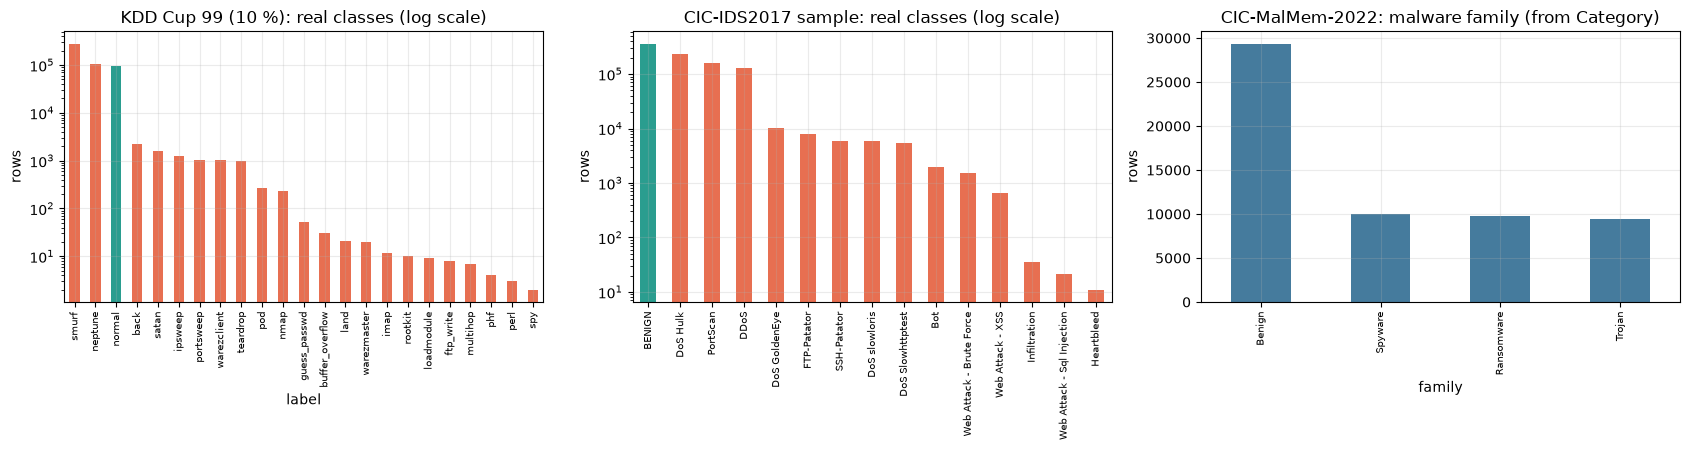

In [6]:
def show_dataset(name, df, label_col, feats, extra_cols=()):
    print(f"==== {name}: shape {df.shape}  ({len(feats)} numerical features used)")
    print("feature names:", feats[:12], "..." if len(feats) > 12 else "")
    vc = df[label_col].value_counts()
    print("original label values and counts:"); display(vc.rename("rows").to_frame().T)
    return vc

vc_kdd = show_dataset("KDD Cup 99 (10 %)", kdd, "label", KDD_NUM)
print("by family:", kdd["family"].value_counts().to_dict())
vc_cic = pd.Series(CIC_LAB).value_counts()
print(f"==== CIC-IDS2017 (cached sample: all attacks + 16 % of benign): shape {CIC_SHAPE}  ({len(CIC_FEATS)} numerical features used)")
print("feature names:", CIC_FEATS[:12], "...")
print("original label values and counts:"); display(vc_cic.rename("rows").to_frame().T)
mal_feats = [c for c in mal.columns if c not in ("Category", "Class", "Filename")]
mal["family"] = mal["Category"].str.split("-").str[0]
vc_mal = show_dataset("CIC-MalMem-2022", mal, "Category", mal_feats)
vc_mal_fam = mal["family"].value_counts()
print("Class column:", mal["Class"].value_counts().to_dict())
print("DARKNET: BLOCKED (no public CSV reachable; Tables 6 / Figure 5 cannot be reproduced)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
vc_kdd.plot.bar(ax=ax[0], color=["#2a9d8f" if l == "normal" else "#e76f51" for l in vc_kdd.index]); ax[0].set_yscale("log"); ax[0].set_title("KDD Cup 99 (10 %): real classes (log scale)")
vc_cic.plot.bar(ax=ax[1], color=["#2a9d8f" if l == "BENIGN" else "#e76f51" for l in vc_cic.index]); ax[1].set_yscale("log"); ax[1].set_title("CIC-IDS2017 sample: real classes (log scale)")
vc_mal_fam.plot.bar(ax=ax[2], color="#457b9d"); ax[2].set_title("CIC-MalMem-2022: malware family (from Category)")
for a in ax: a.set_ylabel("rows"); a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

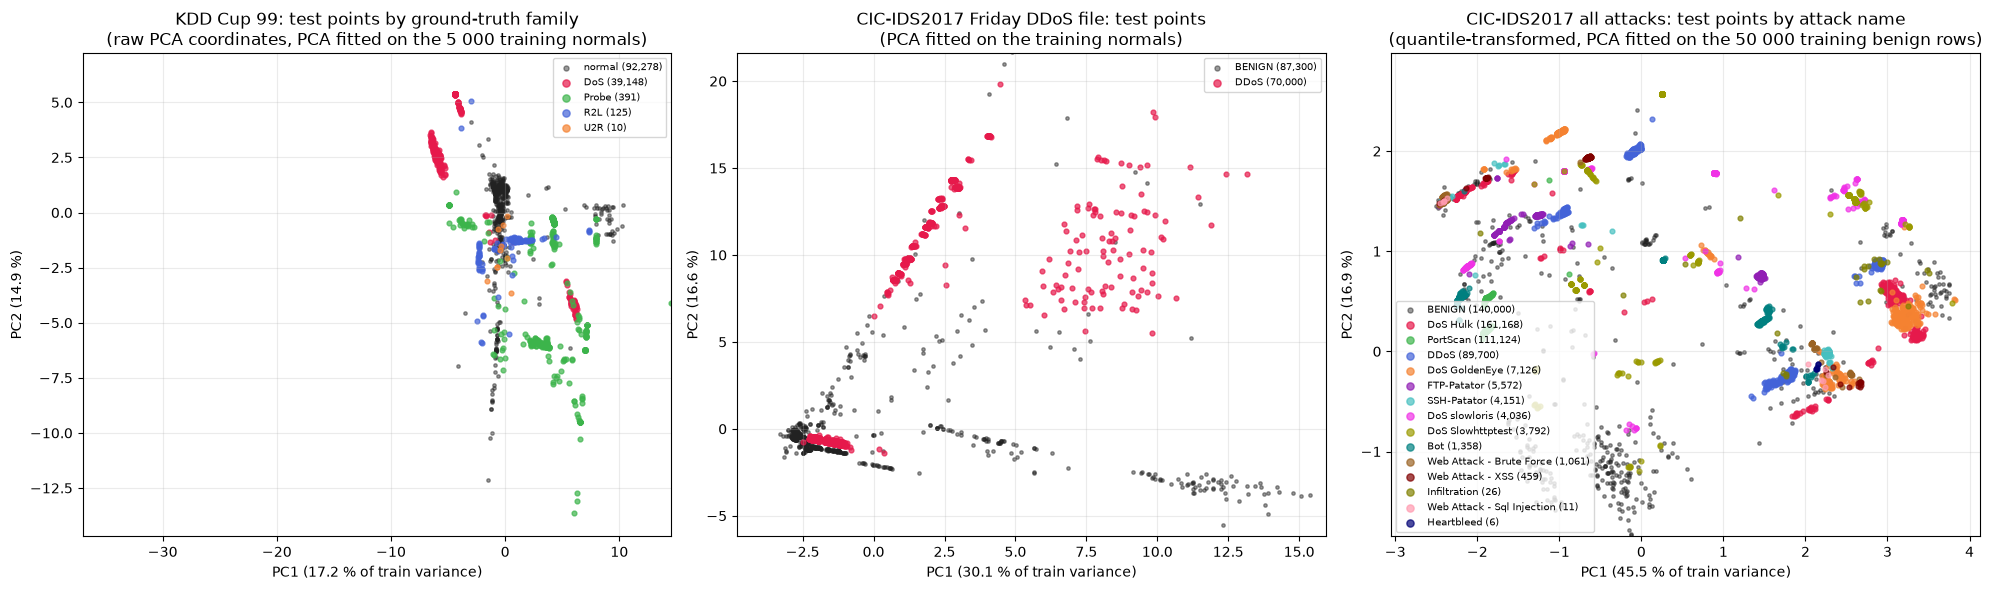

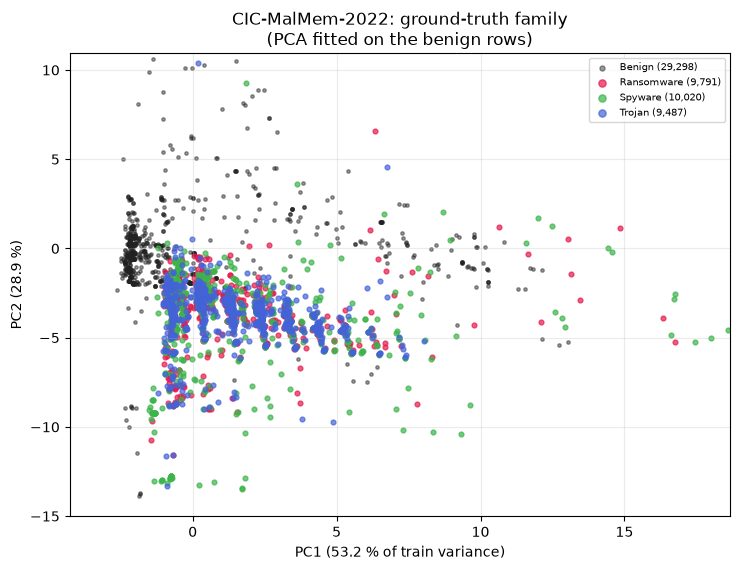

No angle encoding is used in this paper, so there is no [0, pi]-scaled scatter.


In [7]:
PALETTE = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#46c0c0", "#f032e6", "#9a9a00", "#008080", "#9a6324", "#800000", "#808000", "#ff9bb0", "#000075", "#2ca02c"]
def scatter_pca(Ztrain, groups, title, ax, max_per_group=700, seed=SEED):
    # groups: dict label -> standardized/transformed matrix. PCA fitted on Ztrain (training normals). The view is clipped to the 0.5-99.5 % range of the plotted points.
    pca = PCA(n_components=2, random_state=SEED).fit(Ztrain)
    rs = np.random.default_rng(seed)
    allP, k = [], 0
    for lab, Z in groups.items():
        if len(Z) == 0: continue
        sel = rs.choice(len(Z), min(max_per_group, len(Z)), replace=False)
        P = pca.transform(Z[sel]); allP.append(P)
        is_norm = lab in ("normal", "BENIGN", "Benign")
        col = "#222222" if is_norm else PALETTE[k % len(PALETTE)]
        if not is_norm: k += 1
        ax.scatter(P[:, 0], P[:, 1], s=6 if is_norm else 12, alpha=0.45 if is_norm else 0.7, label=f"{lab} ({len(Z):,})", color=col)
    allP = np.vstack(allP); lo, hi = np.quantile(allP, 0.005, axis=0), np.quantile(allP, 0.995, axis=0); pad = 0.1 * (hi - lo)
    ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f} % of train variance)"); ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f} %)")
    ax.set_title(title); ax.legend(fontsize=7, markerscale=1.5, loc="best")

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
# KDD: colour by attack family (and normal)
g = {"normal": KDD["Zn"]}
for fam in ["DoS", "Probe", "R2L", "U2R"]:
    g[fam] = KDD["Za"][KDD["fam_a"] == fam]
scatter_pca(KDD["Ztr"], g, "KDD Cup 99: test points by ground-truth family\n(raw PCA coordinates, PCA fitted on the 5 000 training normals)", ax[0])
# CIC DDoS experiment
scatter_pca(DDOS["Ztr"], {"BENIGN": DDOS["Zn"], "DDoS": DDOS["Za"]}, "CIC-IDS2017 Friday DDoS file: test points\n(PCA fitted on the training normals)", ax[1])
# CIC all attacks: colour by attack name
labs = pd.Series(RL["lab_ta"]).value_counts().index.tolist()
g = {"BENIGN": RL["Ztn"]}
for lab in labs: g[lab] = RL["Zta"][RL["lab_ta"] == lab]
scatter_pca(RL["Ztr"], g, "CIC-IDS2017 all attacks: test points by attack name\n(quantile-transformed, PCA fitted on the 50 000 training benign rows)", ax[2], max_per_group=500)
plt.tight_layout(); plt.show()

# CIC-MalMem-2022: standardized features, PCA, colour by Category (used by Appendix C)
mal_X = mal[mal_feats].to_numpy(float)
mal_sc = StandardScaler().fit(mal_X[:, mal_X.std(0) > 0])
mal_Z = mal_sc.transform(mal_X[:, mal_X.std(0) > 0])
fig, ax = plt.subplots(figsize=(7.5, 5.8))
benign_mask = (mal["family"] == "Benign").to_numpy()
g = {"Benign": mal_Z[benign_mask]}
for cat in [c for c in mal["family"].unique() if c != "Benign"]: g[cat] = mal_Z[mal["family"].to_numpy() == cat]
scatter_pca(mal_Z[benign_mask], g, "CIC-MalMem-2022: ground-truth family\n(PCA fitted on the benign rows)", ax, max_per_group=800)
plt.tight_layout(); plt.show()
print("No angle encoding is used in this paper, so there is no [0, pi]-scaled scatter.")

## Quantum Circuit Architecture

NOT_APPLICABLE: the paper analyses fault-tolerant quantum subroutines (phase estimation, amplitude estimation, pure-state tomography, QRAM access) through their *query complexity* and through classical simulations of their approximation errors; it gives no gate-level circuit and executes none (Figure 3 is a block diagram of the pipeline, not a circuit). The only gate-level quantity, the QRAM resource count of Section 5.8, comes from an external tool (Di Matteo et al.) and is only re-computed arithmetically in section 12.

## 3. The simulator: classical PCA and the quantum error models

Step 1 of the paper's methodology is to *model the quantum algorithm with a classical program that adds the errors the theorems allow*. Below, `fit_svd` is exact classical PCA (via the SVD of the training matrix `X`, singular values `sigma_i`,
eigenvalues `lambda_i = sigma_i^2`), and `quantum_components` is its simulated quantum counterpart:

1. **Consistent phase estimation** gives every singular value with an error of at most `eps` (the same error each time the same singular value is estimated).
2. **Quantum binary search** (Theorem B.8) finds a threshold `theta` such that the singular values above it keep a share `p` of the variance, up to an error `eta`.
3. **Singular-vector extraction** (Theorem B.9) returns the selected right singular vectors through pure-state **tomography** with `l2` error `delta`.
4. For the minor components, the same extraction with the condition `sigma_est < theta_min` instead (flip of the comparison in Alg. 4).

The detectors then use these *noisy* components exactly like the classical ones.

In [8]:
# ---------------------------------------------------------------- exact (classical) PCA
def fit_svd(Z, center=False):
    mean = Z.mean(0) if center else np.zeros(Z.shape[1])
    U, S, Vt = np.linalg.svd(Z - mean, full_matrices=False)
    return dict(S=S, V=Vt, mean=mean, n=Z.shape[0], d=Z.shape[1], lam=S ** 2, ratio=S ** 2 / (S ** 2).sum())

def classical_components(M, p=None, k=None, minor_cov=None):
    kk = k if k is not None else int(np.searchsorted(np.cumsum(M["ratio"]), p) + 1)
    q = int((M["lam"] / M["n"] < minor_cov).sum()) if minor_cov else 0
    maj = np.arange(kk); mino = np.arange(len(M["S"]) - q, len(M["S"]))
    out = dict(k=kk, q=q, major=(M["V"][maj], M["lam"][maj]), minor=None, idx_major=maj, idx_minor=mino)
    if q: out["minor"] = (M["V"][mino], M["lam"][mino])
    return out

# ---------------------------------------------------------------- simulated quantum subroutines
class QDevice:
    """One simulated fault-tolerant machine: consistent phase estimation = a fixed error pattern u in [-1, 1]^d (CHOICE)."""
    def __init__(self, M, seed):
        self.M, self.rng = M, np.random.default_rng(seed)
        self.u = self.rng.uniform(-1, 1, size=M["d"])
    def sigma_est(self, eps):
        return np.abs(self.M["S"] + eps * self.u)          # |sigma_est - sigma| <= eps

def q_binary_search(S_est, ratio, p, eta, rng, n_iter=40):
    """Bisection for the largest theta whose kept variance (plus an amplitude-estimation error U(-eta, eta)) is still >= p."""
    lo, hi = 0.0, float(S_est.max())
    for _ in range(n_iter):
        th = 0.5 * (lo + hi)
        est = ratio[S_est >= th].sum() + rng.uniform(-eta, eta)
        if est >= p: lo = th
        else: hi = th
    return lo

def q_tomography(v, delta, rng, mode="measure", divisor=1):
    """l2 tomography of a unit vector.  measure: N = 36 d ln d / (delta^2 divisor) multinomial samples, signs known.  noise: v + delta*u, |u| = 1."""
    d = len(v); v = v / np.linalg.norm(v)
    if mode == "measure":
        N = int(np.ceil(36 * d * np.log(d) / delta ** 2 / divisor))
        counts = rng.multinomial(N, v ** 2 / (v ** 2).sum())
        est = np.sign(v) * np.sqrt(counts / N)
    else:
        u = rng.normal(size=d); u /= np.linalg.norm(u)
        est = v + delta * u
    return est / np.linalg.norm(est)

def quantum_components(M, dev, p, eps_theta, eps, eta, delta, minor_theta=None, mode="measure", divisor=1):
    rng = dev.rng
    S1 = dev.sigma_est(eps_theta)
    theta = q_binary_search(S1, M["ratio"], p, eta, rng)
    S2 = dev.sigma_est(eps)
    maj = np.flatnonzero(S1 >= theta)
    if len(maj) == 0: maj = np.array([int(np.argmax(S1))])
    out = dict(theta=theta, k=len(maj), q=0, idx_major=maj, idx_minor=np.array([], int), minor=None)
    out["major"] = (np.array([q_tomography(M["V"][i], delta, rng, mode, divisor) for i in maj]), np.maximum(S2[maj] ** 2, 1e-12))
    if minor_theta is not None:
        mino = np.flatnonzero((S2 < minor_theta) & ~np.isin(np.arange(M["d"]), maj))
        if len(mino):
            out["q"], out["idx_minor"] = len(mino), mino
            out["minor"] = (np.array([q_tomography(M["V"][i], delta, rng, mode, divisor) for i in mino]), np.maximum(S2[mino] ** 2, 1e-12))
    return out

def subspace_error(M, comps):
    """Mean l2 distance between the extracted and the exact major singular vectors (sign-aligned)."""
    V, _ = comps["major"]; errs = []
    for v, i in zip(V, comps["idx_major"]):
        e = M["V"][i]; errs.append(min(np.linalg.norm(v - e), np.linalg.norm(v + e)))
    return float(np.mean(errs))

## 4. The three detectors

* `pcc_scores` returns the sums `T` of the paper for the major components and (if given) the minor ones; `kinds` selects how `y_i` is computed: `dot` = `e_i . z` (PCC), `cos` = cosine similarity, `corr` = Pearson correlation between `z` and `e_i` (the last two make the *Ensemble PCC*).
* `detect_pcc` turns false-alarm rates `alpha` into one threshold per sum (the `(1-alpha)` quantile on the training normals) and flags a sample when **any** sum exceeds its threshold.
* `sse_scores` is the reconstruction-loss score `sum (z - E E^T z)^2`.

Metrics always treat the attack as the positive class and are reported in %. Because the paper's Table 5 numbers imply a different attack share than the one stated in the text, `reweight` can re-compute precision, F1 and accuracy for another attack share from the true/false positive rates.

In [9]:
def pcc_scores(Z, comps, kinds=("dot",), use_minor=False):
    cols = []
    for part in ("major", "minor") if use_minor else ("major",):
        if comps.get(part) is None: continue
        V, lam = comps[part]
        Vn = V / np.linalg.norm(V, axis=1, keepdims=True)
        for kind in kinds:
            if kind == "dot":
                Y = Z @ V.T
            elif kind == "cos":
                Y = (Z @ Vn.T) / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
            else:                                   # Pearson correlation between the sample and the component
                Zc = Z - Z.mean(1, keepdims=True); Vc = Vn - Vn.mean(1, keepdims=True)
                Y = (Zc @ Vc.T) / np.maximum(np.linalg.norm(Zc, axis=1, keepdims=True), 1e-12) / np.maximum(np.linalg.norm(Vc, axis=1), 1e-12)
            cols.append((Y ** 2 / lam).sum(1))
    return np.column_stack(cols)

def prf(tp, fp, fn, tn):
    rec = tp / max(tp + fn, 1e-12); prec = tp / max(tp + fp, 1e-12)
    f1 = 2 * prec * rec / max(prec + rec, 1e-12); acc = (tp + tn) / (tp + fp + fn + tn)
    return 100 * np.array([rec, prec, f1, acc])

def detect_pcc(Str, Sn, Sa, alphas=ALPHAS):
    rows = []
    for a in alphas:
        c = np.quantile(Str, 1 - a / 100, axis=0)
        pa, pn = (Sa > c).any(1), (Sn > c).any(1)
        tp, fn, fp, tn = pa.sum(), (~pa).sum(), pn.sum(), (~pn).sum()
        rows.append([a, *prf(tp, fp, fn, tn), tp / (tp + fn), fp / (fp + tn)])
    return pd.DataFrame(rows, columns=["alpha", "Recall", "Precision", "F1", "Accuracy", "TPR", "FPR"]).set_index("alpha")

def reweight(tpr, fpr, share):
    tp, fn, fp, tn = share * tpr, share * (1 - tpr), (1 - share) * fpr, (1 - share) * (1 - fpr)
    return prf(tp, fp, fn, tn)           # recall, precision, F1, accuracy (%)

def sse_scores(Z, mean, E, chunk=40_000):
    out = np.empty(len(Z))
    for s in range(0, len(Z), chunk):
        X = Z[s:s + chunk] - mean
        R = X - (X @ E.T) @ E
        out[s:s + chunk] = (R ** 2).sum(1)
    return out

def run_pcc(Zcal, Zn, Za, comps, kinds=("dot",), use_minor=False):
    # Zcal: sample used to calibrate the thresholds (see the CHOICE table)
    f = lambda Z: pcc_scores(Z, comps, kinds, use_minor)
    return detect_pcc(f(Zcal), f(Zn), f(Za))

def mean_std(frames):
    cat = pd.concat(frames, keys=range(len(frames)))
    return cat.groupby(level=1).mean(), cat.groupby(level=1).std().fillna(0.0)
PAPER_METRICS = ["Recall", "Precision", "F1", "Accuracy"]

## 5. KDD Cup 99: PCC with major components (paper Table 3) and with major + minor components (Appendix D, Table C.7)

Classical model: `PCA70` (the smallest number of components keeping 70 % of the variance) and, for Table C.7, the minor components with covariance eigenvalue below 0.20.
Quantum model: `QPCA70` with the paper's error parameters `p = 0.70, eps_theta = eps = 1, eta = 0.1, delta = 0.1`; the table shows the mean over `N_QSEEDS` independent simulated devices.

In [10]:
PAPER_T3 = pd.DataFrame({  # alpha: (recall c, recall q, precision c, q, F1 c, q, accuracy c, q)
    1: [93.14, 92.84, 98.63, 98.68, 95.81, 95.67, 97.55, 97.47], 2: [93.19, 92.88, 98.18, 98.23, 95.62, 95.48, 97.43, 97.35],
    4: [96.04, 95.75, 96.51, 96.57, 96.28, 96.15, 97.76, 97.69], 6: [98.51, 98.12, 94.20, 92.21, 96.30, 96.12, 97.72, 97.62],
    8: [98.67, 98.36, 92.01, 92.07, 95.22, 95.11, 97.02, 96.69], 10: [99.44, 99.12, 90.05, 90.10, 94.51, 94.40, 96.53, 96.46]}).T
PAPER_C7 = pd.DataFrame({
    1: [98.62, 98.68, 97.26, 96.99, 97.94, 97.83, 98.75, 98.68], 2: [98.66, 98.73, 95.96, 95.58, 97.29, 97.13, 98.35, 98.24],
    4: [98.80, 98.90, 91.61, 91.42, 95.07, 95.01, 96.91, 96.88], 6: [98.84, 98.99, 88.88, 88.25, 93.60, 93.31, 95.78, 95.73],
    8: [98.93, 99.27, 86.11, 85.84, 92.08, 92.07, 94.88, 94.85], 10: [99.59, 99.87, 83.25, 83.14, 90.69, 90.74, 93.85, 93.87]}).T
for T in (PAPER_T3, PAPER_C7):
    T.columns = pd.MultiIndex.from_product([PAPER_METRICS, ["c", "q"]]); T.index.name = "alpha"

def side_by_side(paper, c_mean, q_mean, q_std=None):
    cols = {}
    for m in PAPER_METRICS:
        cols[(m, "paper c")] = paper[(m, "c")]; cols[(m, "ours c")] = c_mean[m]
        cols[(m, "paper q")] = paper[(m, "q")]; cols[(m, "ours q")] = q_mean[m]
    return pd.DataFrame(cols).round(2)

def within(df, tol=TOL_PTS):
    """share of (paper, ours) pairs within tol percentage points"""
    res = {}
    for side in ("c", "q"):
        diffs = np.concatenate([(df[(m, f"paper {side}")] - df[(m, f"ours {side}")]).abs().to_numpy() for m in PAPER_METRICS])
        res[side] = float((diffs <= tol).mean())
    return res

# ---------------- exact model
M_kdd = fit_svd(KDD["Ztr"])
cc_major = classical_components(M_kdd, p=Q_KDD["p"])
cc_both = classical_components(M_kdd, p=Q_KDD["p"], minor_cov=MINOR_COV_EIG)
print(f"classical PCA70: k = {cc_major['k']} major components (variance kept {100*M_kdd['ratio'][:cc_major['k']].sum():.1f} %), q = {cc_both['q']} minor components (cov. eigenvalue < {MINOR_COV_EIG})   [paper: 10 major, 6 minor]")
print("largest singular values:", np.round(M_kdd["S"][:6], 1), "| smallest:", np.round(M_kdd["S"][-4:], 2))

theta_min_kdd = math.sqrt(MINOR_COV_EIG * M_kdd["n"])
def kdd_quantum(use_minor, seed):
    dev = QDevice(M_kdd, seed)
    qc = quantum_components(M_kdd, dev, **Q_KDD, minor_theta=theta_min_kdd if use_minor else None)
    df = run_pcc(KDD["Zcal"], KDD["Zn"], KDD["Za"], qc, use_minor=use_minor)
    return df, (qc["k"], qc["q"], subspace_error(M_kdd, qc))

# Table 3: major components only
c3 = run_pcc(KDD["Zcal"], KDD["Zn"], KDD["Za"], cc_major)
runs = [kdd_quantum(False, SEED + 100 + s) for s in range(N_QSEEDS)]
q3, q3_sd = mean_std([r[0] for r in runs])
print(f"quantum draws: k_est = {[r[1][0] for r in runs]}, mean l2 error of the extracted singular vectors = {np.mean([r[1][2] for r in runs]):.3f} (budget delta = {Q_KDD['delta']})")
T3 = side_by_side(PAPER_T3, c3, q3)
print("Table 3 (KDD, PCC with major components, %): paper vs this notebook"); display(T3)
print("share of cells within", TOL_PTS, "points of the paper:", within(T3))
print("max |quantum - classical| in this notebook (points):", float((q3[PAPER_METRICS] - c3[PAPER_METRICS]).abs().max().max().round(2)), "| paper's max gap:", float(max((PAPER_T3[(m, 'c')] - PAPER_T3[(m, 'q')]).abs().max() for m in PAPER_METRICS)))

classical PCA70: k = 9 major components (variance kept 71.0 %), q = 9 minor components (cov. eigenvalue < 0.2)   [paper: 10 major, 6 minor]
largest singular values: [154.5 143.6 100.4  97.4  97.1  89.1] | smallest: [19.21 18.79 12.12  5.25]


quantum draws: k_est = [7, 8, 8, 8, 7, 11, 8, 10, 8, 8], mean l2 error of the extracted singular vectors = 0.004 (budget delta = 0.1)
Table 3 (KDD, PCC with major components, %): paper vs this notebook


Recall                       Precision                            F1                       Accuracy                      
      paper c ours c paper q ours q   paper c ours c paper q ours q paper c ours c paper q ours q  paper c ours c paper q ours q
alpha                                                                                                                           
1       93.14  93.65   92.84  93.66     98.63  96.71   98.68  96.73   95.81  95.16   95.67  95.17    97.55  97.13   97.47  97.14
2       93.19  96.09   92.88  97.35     98.18  95.06   98.23  94.94   95.62  95.57   95.48  96.12    97.43  97.32   97.35  97.64
4       96.04  98.98   95.75  99.01     96.51  91.24   96.57  91.03   96.28  94.95   96.15  94.86    97.76  96.83   97.69  96.77
6       98.51  99.06   98.12  99.10     94.20  87.86   92.21  87.62   96.30  93.13   96.12  93.00    97.72  95.60   97.62  95.52
8       98.67  99.22   98.36  99.25     92.01  84.30   92.07  84.20   95.22  91.15   95.11  91.11    97.02  94.21   96.69  94.17
10      99.44  99.31   99.12  99.30     90.05  81.39   90.10  81.15   94.51  89.46   94.40  89.31    96.53  92.97   96.46  92.86

share of cells within 2.0 points of the paper: {'c': 0.4583333333333333, 'q': 0.4583333333333333}
max |quantum - classical| in this notebook (points): 1.27 | paper's max gap: 1.990000000000009


quantum draws: (k_est, q_est) = [(8, 8), (7, 9), (8, 9), (8, 9), (10, 9), (8, 8), (9, 9), (9, 9), (8, 8), (9, 8)]   [paper: QPCA70 10 major + 7 minor versus classical 10 + 6]
Table C.7 (KDD, PCC with major + minor components, %): paper vs this notebook


Recall                       Precision                            F1                       Accuracy                      
      paper c ours c paper q ours q   paper c ours c paper q ours q paper c ours c paper q ours q  paper c ours c paper q ours q
alpha                                                                                                                           
1       98.62  98.85   98.68  98.86     97.26  95.75   96.99  95.78   97.94  97.27   97.83  97.29    98.75  98.33   98.68  98.35
2       98.66  99.04   98.73  99.07     95.96  92.24   95.58  92.14   97.29  95.52   97.13  95.48    98.35  97.21   98.24  97.18
4       98.80  99.26   98.90  99.26     91.61  86.22   91.42  86.02   95.07  92.28   95.01  92.16    96.91  95.01   96.88  94.92
6       98.84  99.48   98.99  99.44     88.88  81.94   88.25  82.00   93.60  89.86   93.31  89.88    95.78  93.25   95.73  93.27
8       98.93  99.72   99.27  99.70     86.11  77.66   85.84  77.55   92.08  87.32   92.07  87.24    94.88  91.29   94.85  91.23
10      99.59  99.79   99.87  99.76     83.25  73.14   83.14  73.03   90.69  84.41   90.74  84.32    93.85  88.92   93.87  88.85

share of cells within 2.0 points of the paper: {'c': 0.5, 'q': 0.5}
max |quantum - classical| in this notebook (points): 0.2


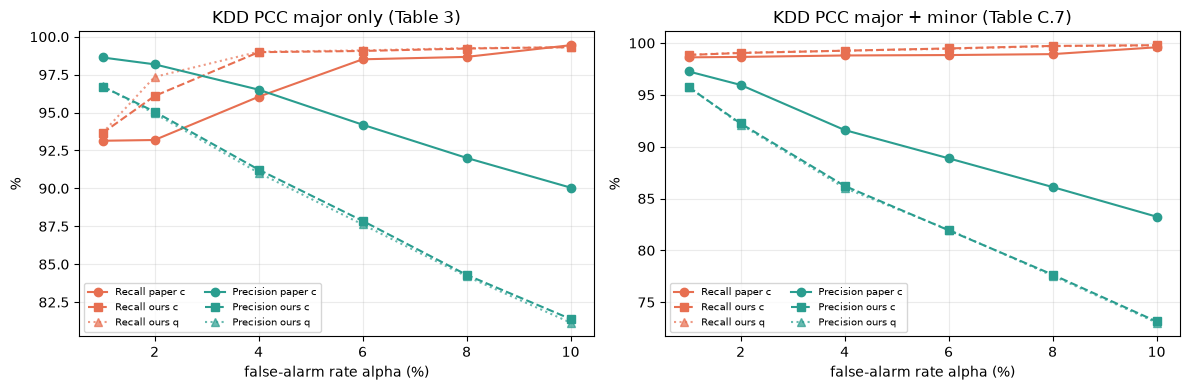

In [11]:
# Table C.7: major + minor components
c7 = run_pcc(KDD["Zcal"], KDD["Zn"], KDD["Za"], cc_both, use_minor=True)
runs7 = [kdd_quantum(True, SEED + 200 + s) for s in range(N_QSEEDS)]
q7, q7_sd = mean_std([r[0] for r in runs7])
print(f"quantum draws: (k_est, q_est) = {[r[1][:2] for r in runs7]}   [paper: QPCA70 10 major + 7 minor versus classical 10 + 6]")
C7 = side_by_side(PAPER_C7, c7, q7)
print("Table C.7 (KDD, PCC with major + minor components, %): paper vs this notebook"); display(C7)
print("share of cells within", TOL_PTS, "points of the paper:", within(C7))
print("max |quantum - classical| in this notebook (points):", float((q7[PAPER_METRICS] - c7[PAPER_METRICS]).abs().max().max().round(2)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, (tab, nm) in zip(ax, ((T3, "major only (Table 3)"), (C7, "major + minor (Table C.7)"))):
    for m, col in zip(("Recall", "Precision"), ("#e76f51", "#2a9d8f")):
        a_.plot(tab.index, tab[(m, "paper c")], "o-", color=col, label=f"{m} paper c"); a_.plot(tab.index, tab[(m, "ours c")], "s--", color=col, label=f"{m} ours c")
        a_.plot(tab.index, tab[(m, "ours q")], "^:", color=col, alpha=0.7, label=f"{m} ours q")
    a_.set_xlabel("false-alarm rate alpha (%)"); a_.set_ylabel("%"); a_.set_title(f"KDD PCC {nm}"); a_.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

### Supervised reference on the same inputs (not in the paper)

The detectors above never see an attack. To show what labelled data would add, a Random Forest and an RBF-SVC are trained on the **same standardized training normals plus 5 000 labelled attacks** drawn from the attack rows that are *not* in the test set, using the top-`k` classical principal components as inputs (the same reduced features the PCC projects on). To keep the RBF-SVC fast, both models are scored on a random subsample of 40 000 test rows (same rows for both).

In [12]:
def supervised_reference(S, M, k, n_attack=5000, max_test=40_000, seed=SEED):
    rs = np.random.default_rng(seed)
    pool = S["Zpool"][rs.choice(len(S["Zpool"]), min(n_attack, len(S["Zpool"])), replace=False)]
    Xl = np.vstack([S["Ztr"], pool]); yl = np.r_[np.zeros(len(S["Ztr"])), np.ones(len(pool))]
    P = M["V"][:k]
    f = lambda Z: Z @ P.T
    Xte = np.vstack([S["Zn"], S["Za"]]); yte = np.r_[np.zeros(len(S["Zn"])), np.ones(len(S["Za"]))]
    sub = rs.choice(len(Xte), min(max_test, len(Xte)), replace=False); Xte, yte = Xte[sub], yte[sub]      # random test subsample (speed of the RBF-SVC)
    out = {}
    for name, clf in (("RandomForest", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)),
                      ("SVC (rbf)", SVC(kernel="rbf", C=1.0, gamma="scale"))):
        t = time.time(); clf.fit(f(Xl), yl); pred = clf.predict(f(Xte)); dt = time.time() - t
        tp = ((pred == 1) & (yte == 1)).sum(); fp = ((pred == 1) & (yte == 0)).sum(); fn = ((pred == 0) & (yte == 1)).sum(); tn = ((pred == 0) & (yte == 0)).sum()
        out[name] = [*prf(tp, fp, fn, tn).round(2), round(dt, 1)]
    return pd.DataFrame(out, index=PAPER_METRICS + ["time s"]).T

print(f"KDD: supervised reference on the top-{cc_major['k']} classical principal components (labelled attacks: 5 000)")
display(supervised_reference(KDD, M_kdd, cc_major["k"]))

KDD: supervised reference on the top-9 classical principal components (labelled attacks: 5 000)


,Recall,Precision,F1,Accuracy,time s
RandomForest,99.67,98.92,99.29,99.58,2.4
SVC (rbf),98.84,98.11,98.47,99.08,7.4


## 6. CIC-IDS2017 DDoS: PCC and Ensemble PCC (paper Table 4)

`q1` is the quantum PCC with major **and** minor components (`QPCA70`), `q2` is the quantum **Ensemble** PCC (dot product, cosine similarity and correlation, major and minor: six sums). Parameters of Section 5.4: `eps = eps_theta = 1, eta = 0.1, delta = 0.1`, minor threshold `theta_min` as for KDD.
Our classical columns are the exact-PCA versions of both detectors.

classical PCA70 on DDoS data: k = 6 major, q = 41 minor components (d = 66 features)


quantum draws (k_est, q_est): [(4, 41), (5, 42), (7, 42), (8, 41), (5, 41), (7, 42), (7, 41), (6, 41), (7, 42), (5, 41)]
Table 4 (CIC-IDS2017 DDoS, %): paper (q1 = PCC, q2 = Ensemble) vs this notebook (c = exact PCA, q = simulated quantum)


Recall                                          Precision                                                F1                                          Accuracy                                         
      paper q1 ours c1 ours q1 paper q2 ours c2 ours q2  paper q1 ours c1 ours q1 paper q2 ours c2 ours q2 paper q1 ours c1 ours q1 paper q2 ours c2 ours q2 paper q1 ours c1 ours q1 paper q2 ours c2 ours q2
alpha                                                                                                                                                                                                         
1        36.05   31.30   24.72    39.80   45.95   36.72     96.94   92.04   82.68    95.30   89.56   78.64    52.55   46.71   37.41    56.15   60.74   48.92    70.36   68.22   65.21    71.69   73.56   69.38
2        58.97   44.51   40.09    73.84   68.76   57.77     96.54   90.26   86.87    94.07   86.46   81.55    73.22   59.62   53.86    82.74   76.60   66.06    80.35   73.17   71.05    85.97   81.30   76.41
4        63.30   64.16   55.28    89.61   91.30   77.34     94.36   88.57   84.85    90.79   81.69   77.92    75.77   74.42   66.25    90.19   86.23   76.91    81.56   80.37   75.99    91.13   87.02   80.72
6        63.37   68.93   63.47    96.96   99.75   91.01     91.61   85.05   82.58    87.25   76.86   75.00    74.92   76.15   71.37    91.85   86.82   81.98    80.68   80.78   77.98    92.16   86.53   82.73
8        64.43   72.31   69.62    97.56   99.93   95.45     88.99   82.44   80.08    83.45   72.16   71.46    74.75   77.04   74.25    89.95   83.81   81.66    80.17   80.82   78.92    90.08   82.82   81.10
10       65.90   74.62   73.14    97.78   99.94   97.39     86.92   79.90   77.93    80.44   68.72   67.80    74.97   77.17   75.32    88.27   81.44   79.92    79.96   80.35   78.93    88.16   79.73   78.29

cells within 2.0 points of the paper: PCC 0.21, Ensemble 0.04
Ensemble beats PCC in F1 at alpha >= 2 (this notebook, quantum): True | F1 gain at alpha = 4: 10.7 points (paper: 14.4)
max |quantum - classical| in F1 (points): PCC 9.31 | Ensemble 11.82


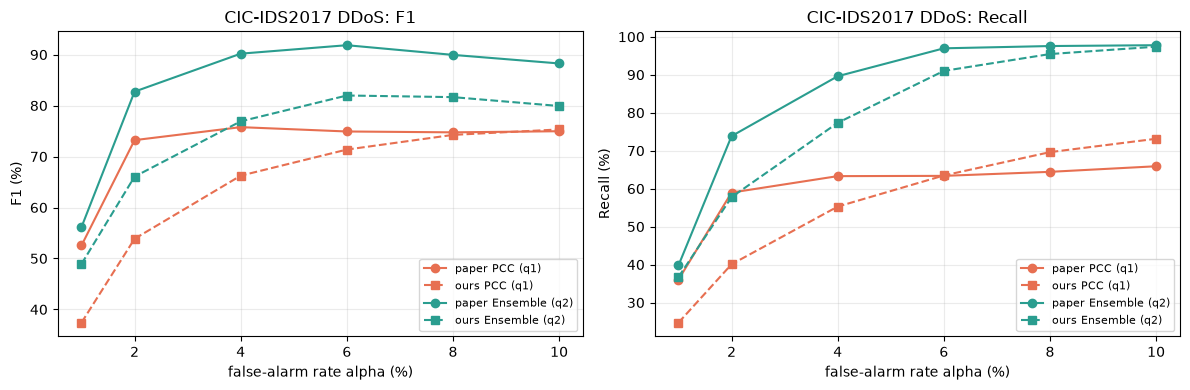

minor components: 41; with singular value < eps=1: 16; < 10: 30; smallest 2.62e-14, median 2.76


Effect of the binary-search error eta on the DDoS detectors (eps = 1, alpha = 4 %):


,eta,k_est (per device),PCC F1 (alpha=4),Ensemble F1 (alpha=4)
0,0.1,"[5, 5, 5, 6, 4, 6, 5, 6, 5, 6]",64.92,74.60
1,0.03,"[6, 6, 6, 6, 6, 6, 6, 6, 6, 6]",66.12,75.08
2,0.01,"[6, 6, 6, 6, 6, 6, 6, 6, 6, 6]",66.12,75.08
3,0.001,"[6, 6, 6, 6, 6, 6, 6, 6, 6, 6]",66.12,75.08
4,classical,[6],74.42,86.23


DDoS: supervised reference on the top-6 classical principal components (labelled DDoS flows: 5 000)


,Recall,Precision,F1,Accuracy,time s
RandomForest,99.63,99.79,99.71,99.74,2.1
SVC (rbf),94.36,97.73,96.02,96.50,22.3


In [13]:
PAPER_T4 = pd.DataFrame({  # alpha: recall q1,q2 | precision q1,q2 | F1 q1,q2 | accuracy q1,q2
    1: [36.05, 39.80, 96.94, 95.30, 52.55, 56.15, 70.36, 71.69], 2: [58.97, 73.84, 96.54, 94.07, 73.22, 82.74, 80.35, 85.97],
    4: [63.30, 89.61, 94.36, 90.79, 75.77, 90.19, 81.56, 91.13], 6: [63.37, 96.96, 91.61, 87.25, 74.92, 91.85, 80.68, 92.16],
    8: [64.43, 97.56, 88.99, 83.45, 74.75, 89.95, 80.17, 90.08], 10: [65.90, 97.78, 86.92, 80.44, 74.97, 88.27, 79.96, 88.16]}).T
PAPER_T4.columns = pd.MultiIndex.from_product([PAPER_METRICS, ["q1", "q2"]]); PAPER_T4.index.name = "alpha"

M_dd = fit_svd(DDOS["Ztr"])
cd_major = classical_components(M_dd, p=Q_DDOS["p"], minor_cov=MINOR_COV_EIG)
print(f"classical PCA70 on DDoS data: k = {cd_major['k']} major, q = {cd_major['q']} minor components (d = {M_dd['d']} features)")
theta_min_dd = math.sqrt(MINOR_COV_EIG * M_dd["n"])

ENS = ("dot", "cos", "corr")
c_pcc = run_pcc(DDOS["Zcal"], DDOS["Zn"], DDOS["Za"], cd_major, use_minor=True)
c_ens = run_pcc(DDOS["Zcal"], DDOS["Zn"], DDOS["Za"], cd_major, kinds=ENS, use_minor=True)
q1_runs, q2_runs, kq = [], [], []
for s in range(N_QSEEDS):
    dev = QDevice(M_dd, SEED + 300 + s)
    qc = quantum_components(M_dd, dev, **Q_DDOS, minor_theta=theta_min_dd)
    q1_runs.append(run_pcc(DDOS["Zcal"], DDOS["Zn"], DDOS["Za"], qc, use_minor=True))
    q2_runs.append(run_pcc(DDOS["Zcal"], DDOS["Zn"], DDOS["Za"], qc, kinds=ENS, use_minor=True))
    kq.append((qc["k"], qc["q"]))
q1, q1_sd = mean_std(q1_runs); q2, q2_sd = mean_std(q2_runs)
print("quantum draws (k_est, q_est):", kq)

cols = {}
for m in PAPER_METRICS:
    cols[(m, "paper q1")] = PAPER_T4[(m, "q1")]; cols[(m, "ours c1")] = c_pcc[m]; cols[(m, "ours q1")] = q1[m]
    cols[(m, "paper q2")] = PAPER_T4[(m, "q2")]; cols[(m, "ours c2")] = c_ens[m]; cols[(m, "ours q2")] = q2[m]
T4 = pd.DataFrame(cols).round(2)
print("Table 4 (CIC-IDS2017 DDoS, %): paper (q1 = PCC, q2 = Ensemble) vs this notebook (c = exact PCA, q = simulated quantum)"); display(T4)
d1 = np.concatenate([(T4[(m, "paper q1")] - T4[(m, "ours q1")]).abs().to_numpy() for m in PAPER_METRICS])
d2 = np.concatenate([(T4[(m, "paper q2")] - T4[(m, "ours q2")]).abs().to_numpy() for m in PAPER_METRICS])
print(f"cells within {TOL_PTS} points of the paper: PCC {np.mean(d1 <= TOL_PTS):.2f}, Ensemble {np.mean(d2 <= TOL_PTS):.2f}")
print("Ensemble beats PCC in F1 at alpha >= 2 (this notebook, quantum):", bool((q2['F1'].loc[2:] > q1['F1'].loc[2:]).all()),
      "| F1 gain at alpha = 4:", round(float(q2['F1'][4] - q1['F1'][4]), 1), "points (paper: 14.4)")
print("max |quantum - classical| in F1 (points): PCC", round(float((q1['F1'] - c_pcc['F1']).abs().max()), 2), "| Ensemble", round(float((q2['F1'] - c_ens['F1']).abs().max()), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, (m, ttl) in zip(ax, (("F1", "F1 (%)"), ("Recall", "Recall (%)"))):
    a_.plot(T4.index, T4[(m, "paper q1")], "o-", color="#e76f51", label="paper PCC (q1)"); a_.plot(T4.index, T4[(m, "ours q1")], "s--", color="#e76f51", label="ours PCC (q1)")
    a_.plot(T4.index, T4[(m, "paper q2")], "o-", color="#2a9d8f", label="paper Ensemble (q2)"); a_.plot(T4.index, T4[(m, "ours q2")], "s--", color="#2a9d8f", label="ours Ensemble (q2)")
    a_.set_xlabel("false-alarm rate alpha (%)"); a_.set_ylabel(ttl); a_.set_title(f"CIC-IDS2017 DDoS: {m}"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

# diagnostic: why is quantum != classical here?  (a) singular values below eps cannot be resolved; (b) the binary-search error eta changes the number of components k
S_min = M_dd["S"][cd_major["idx_minor"]]
print(f"minor components: {cd_major['q']}; with singular value < eps=1: {(S_min < 1).sum()}; < 10: {(S_min < 10).sum()}; smallest {S_min.min():.3g}, median {np.median(S_min):.3g}")
sweep = []
for eta in (0.1, 0.03, 0.01, 0.001):
    ks, f1a, f1b = [], [], []
    for s in range(N_QSEEDS):
        dev = QDevice(M_dd, SEED + 350 + s)
        qc = quantum_components(M_dd, dev, p=Q_DDOS["p"], eps_theta=Q_DDOS["eps_theta"], eps=Q_DDOS["eps"], eta=eta, delta=Q_DDOS["delta"], minor_theta=theta_min_dd)
        ks.append(qc["k"])
        f1a.append(run_pcc(DDOS["Zcal"], DDOS["Zn"], DDOS["Za"], qc, use_minor=True).loc[4, "F1"])
        f1b.append(run_pcc(DDOS["Zcal"], DDOS["Zn"], DDOS["Za"], qc, kinds=ENS, use_minor=True).loc[4, "F1"])
    sweep.append((eta, str(ks), np.mean(f1a), np.mean(f1b)))
sweep = pd.DataFrame(sweep, columns=["eta", "k_est (per device)", "PCC F1 (alpha=4)", "Ensemble F1 (alpha=4)"])
sweep["PCC F1 (alpha=4)"], sweep["Ensemble F1 (alpha=4)"] = sweep["PCC F1 (alpha=4)"].round(2), sweep["Ensemble F1 (alpha=4)"].round(2)
sweep.loc[len(sweep)] = ["classical", str([cd_major["k"]]), round(c_pcc.loc[4, "F1"], 2), round(c_ens.loc[4, "F1"], 2)]
print("Effect of the binary-search error eta on the DDoS detectors (eps = 1, alpha = 4 %):"); display(sweep)

print(f"DDoS: supervised reference on the top-{cd_major['k']} classical principal components (labelled DDoS flows: 5 000)")
display(supervised_reference(DDOS, M_dd, cd_major["k"]))

## 7. CIC-IDS2017, all attacks: PCA reconstruction loss (paper Table 5)

Hyper-parameters are chosen on the **validation** set (number of components `k` and threshold `t` maximising the F1 score), then the model is evaluated once on the test set. The quantum model uses the paper's `eps_theta = eps = 0.3`, `eta = 0.00075` and a variable tomography error `delta`.
`delta` = 0.9 and 2 exceed what real measurement noise can produce for unit vectors, so the sweep uses `noise` mode (a perturbation of norm exactly `delta`, re-normalised). The row `h` uses actual simulated tomography with `delta = 0.01` and the paper's heuristic of **100 times fewer samples**; the rows `meas 0.9` and `meas 2` run the real measurement-based tomography at those nominal `delta` (it is far more accurate than the bound, see section 10).
The threshold `t` is the classical one for all rows, as in the paper (a wrong subspace therefore raises the reconstruction error and flags more points as attacks).

In [14]:
def select_rl(Ztr, Zvn, Zva, k_grid, centered_mean):
    M = fit_svd(Ztr, center=True)
    best = None; rows = []
    for k in k_grid:
        E = M["V"][:k]
        sn, sa = sse_scores(Zvn, M["mean"], E), sse_scores(Zva, M["mean"], E)
        ts = np.quantile(np.r_[sn, sa], np.linspace(0.02, 0.98, 193))
        tp = (sa[:, None] > ts).sum(0); fp = (sn[:, None] > ts).sum(0); fn = len(sa) - tp
        f1 = 2 * tp / (2 * tp + fp + fn); j = int(np.argmax(f1))
        rows.append((k, 100 * M["ratio"][:k].sum(), ts[j], 100 * f1[j]))
        if best is None or f1[j] > best[3] / 100: best = rows[-1]
    return M, best, pd.DataFrame(rows, columns=["k", "variance kept %", "best t", "val F1 %"]).round(3)

M_rl, best_rl, sweep_rl = select_rl(RL["Ztr"], RL["Zvn"], RL["Zva"], RL_K_GRID, None)
display(sweep_rl)
K_RL, T_RL = int(best_rl[0]), float(best_rl[2])
print(f"selected on validation F1: k = {K_RL} components ({best_rl[1]:.2f} % of the variance), t = {T_RL:.3f}   [paper: 12 components, 94.88 %, t = 0.425]")
row12 = sweep_rl[sweep_rl.k == 12].iloc[0]; print(f"paper configuration k = 12: variance kept {row12['variance kept %']:.2f} %, validation-optimal t = {row12['best t']:.3f}, validation F1 {row12['val F1 %']:.2f} %")

def rl_eval(E, t, Zn_, Za_, M=M_rl):
    sn, sa = sse_scores(Zn_, M["mean"], E), sse_scores(Za_, M["mean"], E)
    tp, fn, fp, tn = (sa > t).sum(), (sa <= t).sum(), (sn > t).sum(), (sn <= t).sum()
    return np.r_[prf(tp, fp, fn, tn), tp / (tp + fn), fp / (fp + tn)]

cls_rl = rl_eval(M_rl["V"][:K_RL], T_RL, RL["Ztn"], RL["Zta"])
print("classical test result (stated test composition, in %%): recall %.2f precision %.2f F1 %.2f accuracy %.2f" % tuple(cls_rl[:4]))

# attack share implied by the paper's own classical Table 5 row
pr, pp, pa_ = 99.12 / 100, 91.28 / 100, 98.08 / 100
share_implied = (1 - pa_) / ((1 - pr) + pr * (1 / pp - 1))
print(f"attack share implied by the paper's recall/precision/accuracy = {100*share_implied:.1f} %   (the stated test set has {100*RL_N_TEST_ATTACK/(RL_N_TEST_ATTACK+RL_N_TEST_NORMAL):.1f} % attacks)")

,k,variance kept %,best t,val F1 %
0,4,77.406,1.139,90.318
1,6,85.892,0.734,90.665
2,8,90.110,0.702,92.479
3,10,92.478,0.535,91.356
4,12,94.553,0.299,89.129
5,14,96.060,0.219,90.757
6,16,97.093,0.170,91.933
7,20,98.330,0.092,91.739
8,24,99.051,0.048,90.650
9,32,99.692,0.034,88.963


selected on validation F1: k = 8 components (90.11 % of the variance), t = 0.702   [paper: 12 components, 94.88 %, t = 0.425]
paper configuration k = 12: variance kept 94.55 %, validation-optimal t = 0.299, validation F1 89.13 %


classical test result (stated test composition, in %): recall 97.47 precision 88.10 F1 92.55 accuracy 88.46
attack share implied by the paper's recall/precision/accuracy = 18.6 %   (the stated test set has 73.6 % attacks)


In [15]:
PAPER_T5 = pd.DataFrame({"Recall": [99.12, 99.17, 99.79, 100.0], "Precision": [91.28, 91.23, 71.31, 27.30], "F1": [95.04, 95.03, 83.18, 42.89],
                         "Accuracy": [98.08, 98.08, 92.52, 50.66]}, index=[0.01, 0.1, 0.9, 2.0])
p_target = float(M_rl["ratio"][:K_RL].sum())
rl_rows, rl_rows_rw, rl_k = {}, {}, {}
specs = [(d, "noise", 1) for d in Q_RL["deltas"]] + [("h", "measure", Q_RL["heuristic"])] + [(f"meas {d}", "measure", 1) for d in (0.9, 2.0)]
for name, mode, div in specs:
    delta = 0.01 if name == "h" else (float(name.split()[1]) if isinstance(name, str) else name)
    res, resw, ks = [], [], []
    for s in range(N_QSEEDS):
        dev = QDevice(M_rl, SEED + 400 + s)
        qc = quantum_components(M_rl, dev, p=p_target, eps_theta=Q_RL["eps_theta"], eps=Q_RL["eps"], eta=Q_RL["eta"], delta=delta, mode=mode, divisor=div)
        r = rl_eval(qc["major"][0], T_RL, RL["Ztn"], RL["Zta"]); res.append(r); resw.append(reweight(r[4], r[5], share_implied)); ks.append(qc["k"])
    rl_rows[name], rl_rows_rw[name], rl_k[name] = np.mean(res, 0), np.mean(resw, 0), ks
T5 = pd.DataFrame({k: v[:4] for k, v in rl_rows.items()}, index=PAPER_METRICS).T.round(2)
T5w = pd.DataFrame({k: v for k, v in rl_rows_rw.items()}, index=PAPER_METRICS).T.round(2)
T5.loc["classical"] = cls_rl[:4].round(2)
T5w.loc["classical"] = reweight(cls_rl[4], cls_rl[5], share_implied).round(2)
print("number of components found by the simulated quantum binary search (per seed):", rl_k)
print("Table 5 -- this notebook, stated test composition (140 000 normal + 389 590 attacks):"); display(T5)
print(f"Table 5 -- this notebook, re-weighted to the paper-implied attack share {100*share_implied:.1f} % (same TPR/FPR):"); display(T5w)
print("Table 5 -- paper:"); display(PAPER_T5)
mono = lambda df: bool((np.diff(df.loc[[0.01, 0.1, 0.9, 2.0], "Recall"]) >= -0.5).all() and (np.diff(df.loc[[0.01, 0.1, 0.9, 2.0], "Precision"]) <= 0.5).all())
print("recall rises and precision falls with delta (this notebook):", mono(T5), "| classical equals quantum at delta = 0.01 (F1 gap):", round(abs(T5.loc[0.01, "F1"] - T5.loc["classical", "F1"]), 2), "points")

number of components found by the simulated quantum binary search (per seed): {0.01: [8, 8, 8, 8, 8, 8, 8, 8, 8, 8], 0.1: [8, 8, 8, 8, 8, 8, 8, 8, 8, 8], 0.9: [8, 8, 8, 8, 8, 8, 8, 8, 8, 8], 2.0: [8, 8, 8, 8, 8, 8, 8, 8, 8, 8], 'h': [8, 8, 8, 8, 8, 8, 8, 8, 8, 8], 'meas 0.9': [8, 8, 8, 8, 8, 8, 8, 8, 8, 8], 'meas 2.0': [8, 8, 8, 8, 8, 8, 8, 8, 8, 8]}
Table 5 -- this notebook, stated test composition (140 000 normal + 389 590 attacks):


,Recall,Precision,F1,Accuracy
0.01,97.40,88.10,92.52,88.41
0.1,98.27,86.53,92.02,87.47
0.9,100.00,73.61,84.80,73.62
2.0,100.00,73.56,84.77,73.56
h,97.47,88.11,92.55,88.46
meas 0.9,96.89,87.92,92.19,87.92
meas 2.0,97.77,87.31,92.25,87.91
classical,97.47,88.10,92.55,88.46


Table 5 -- this notebook, re-weighted to the paper-implied attack share 18.6 % (same TPR/FPR):


,Recall,Precision,F1,Accuracy
0.01,97.40,37.73,54.39,69.69
0.1,98.27,34.46,51.02,64.99
0.9,100.00,18.59,31.35,18.74
2.0,100.00,18.55,31.30,18.55
h,97.47,37.75,54.42,69.71
meas 0.9,96.89,37.34,53.90,69.26
meas 2.0,97.77,36.04,52.67,67.38
classical,97.47,37.74,54.41,69.70


Table 5 -- paper:


,Recall,Precision,F1,Accuracy
0.01,99.12,91.28,95.04,98.08
0.10,99.17,91.23,95.03,98.08
0.90,99.79,71.31,83.18,92.52
2.00,100.00,27.30,42.89,50.66


recall rises and precision falls with delta (this notebook): True | classical equals quantum at delta = 0.01 (F1 gap): 0.03 points


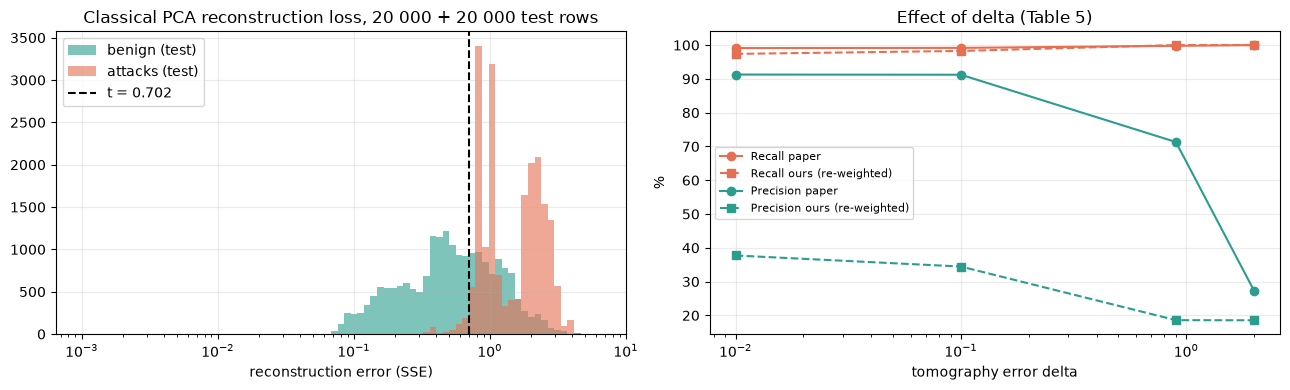

Classical detection rate per attack name:


label,DoS Hulk,PortScan,DDoS,DoS GoldenEye,FTP-Patator,SSH-Patator,DoS slowloris,DoS Slowhttptest,Bot,Web Attack - Brute Force,Web Attack - XSS,Infiltration,Web Attack - Sql Injection,Heartbleed
detected %,97.3,100.0,100.0,93.2,99.9,3.5,99.7,99.9,37.0,84.7,96.3,100.0,9.1,100.0
test rows,161168.0,111124.0,89700.0,7126.0,5572.0,4151.0,4036.0,3792.0,1358.0,1061.0,459.0,26.0,11.0,6.0


In [16]:
# the same sweep as a figure: attack score distribution versus the fixed threshold
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sn_c = sse_scores(RL["Ztn"][:20000], M_rl["mean"], M_rl["V"][:K_RL]); sa_c = sse_scores(RL["Zta"][:20000], M_rl["mean"], M_rl["V"][:K_RL])
bins = np.geomspace(1e-3, max(sn_c.max(), sa_c.max()), 80)
ax[0].hist(sn_c, bins, alpha=0.6, label="benign (test)", color="#2a9d8f"); ax[0].hist(sa_c, bins, alpha=0.6, label="attacks (test)", color="#e76f51")
ax[0].axvline(T_RL, color="k", ls="--", label=f"t = {T_RL:.3f}"); ax[0].set_xscale("log"); ax[0].set_xlabel("reconstruction error (SSE)"); ax[0].set_title("Classical PCA reconstruction loss, 20 000 + 20 000 test rows"); ax[0].legend()
for col, c in (("Recall", "#e76f51"), ("Precision", "#2a9d8f")):
    xs = [0.01, 0.1, 0.9, 2.0]
    ax[1].plot(xs, [PAPER_T5.loc[x, col] for x in xs], "o-", color=c, label=f"{col} paper"); ax[1].plot(xs, [T5w.loc[x, col] for x in xs], "s--", color=c, label=f"{col} ours (re-weighted)")
ax[1].set_xscale("log"); ax[1].set_xlabel("tomography error delta"); ax[1].set_ylabel("%"); ax[1].set_title("Effect of delta (Table 5)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# per-attack detection rate of the classical model (test set)
sa_all = sse_scores(RL["Zta"], M_rl["mean"], M_rl["V"][:K_RL])
per = pd.DataFrame({"label": RL["lab_ta"], "hit": sa_all > T_RL}).groupby("label")["hit"].agg(["mean", "count"]).sort_values("count", ascending=False)
per["mean"] = (100 * per["mean"]).round(1); per.columns = ["detected %", "test rows"]; print("Classical detection rate per attack name:"); display(per.T)

## 8. DARKNET (paper Table 6 and Figure 5): blocked

CIC-Darknet2020 (85 features, Tor/VPN versus normal traffic) is not mirrored on Hugging Face and the University of New Brunswick links return an HTML page, not the CSV (cell in section 1). Nothing is substituted. The numbers of the paper that cannot be checked here:
Table 6 (recall 84.17 / precision 73.71 / F1 78.59 / accuracy 81.35 for the classical model, 84.40 / 73.18 / 78.39 / 81.07 for the quantum model with the heuristic) and the 1e8-sample crossover of Figure 5.
If you have `Darknet.CSV`, drop it into `DATA_DIR` and reuse `build_pcc_split`, `fit_svd`, `sse_scores` and `quantum_components` above: 50 000 training normals, 20 000 + 10 000 validation, 21 000 + 14 000 test, standardized, 35 components, `t = 0.443`, `eps = 0.35`, `eta = 0.0011`.

## 9. Running-time analysis (paper Section 5.3 to 5.6, Figure 4, Step 2 and 3 of the methodology)

Step 2 of the methodology: measure, on the real data, the quantities that appear in the quantum running-time theorems.

| symbol | meaning | measured as |
|---|---|---|
| `n`, `d` | rows, features of the training matrix `X` | shape |
| `k`, `q` | number of major / minor components | classical choice (the quantum draws give about the same) |
| `p`, `p_min` | share of the variance kept by the major / minor components | from the singular values |
| `\|X\|`, `theta`, `sigma_min` | largest singular value, threshold below the `k`-th, smallest singular value | from the SVD (`theta` = the smallest kept singular value, **CHOICE**) |
| `mu(X)` | normalisation of the quantum data structure, Definition B.3: the smaller of `\|X\|_F` and `min_p sqrt(s_2p(X) * s_2(1-p)(X^T))` | grid search over `p` |
| `eps`, `eta`, `delta` | the error parameters of the experiments above | the paper's values |

Step 3: the quantum query count
`Q_major = mu/(eps*eta) * log2(mu/eps) + d*k*(|X|/theta)*(mu/eps) * log2(k)*log2(d) / (sqrt(p)*delta^2)`,
`Q_minor = (theta_min/sigma_min) * (mu/eps) * q*d / sqrt(p_min)`
is compared with the classical `n*d*k*log2(k)` (randomized PCA) or `n*d^2` (full SVD). **How the data grow is a modelling choice**: when `n` grows, `|X|`, `theta`, `mu` and the absolute error `eps` all scale with `sqrt(n)`, so the ratios `mu/eps` and `|X|/theta` that enter the cost are kept at the values measured above
(equivalent to a constant *relative* error). The cost is then independent of `n` (the polylogarithmic dependence of the theorems is dropped) and linear in `d` through the explicit factor. The `O~` constants are set to 1. Because this assumption is the weakest link, the table also gives the **other extreme**: an *absolute* `eps` that does not grow with the data, for which the quantum cost grows like `sqrt(n)`. The truth for a given application lies between the two crossover columns. `KAPPA_EFF` (config cell) discards singular values below `|X|/KAPPA_EFF` (numerically zero, e.g. perfectly collinear flow features) when `sigma_min` and the number of minor components enter `Q_minor`; without it `theta_min/sigma_min` is astronomically large (see the printed `sigma_min_raw`).

In [17]:
def mu_param(X, grid=np.linspace(0, 1, 21)):
    A = np.abs(X); fro = float(np.linalg.norm(X)); best = (fro, "Frobenius")
    for p in grid:
        s_row = ((A > 0).astype(float) if p == 0 else A ** (2 * p)).sum(1).max()            # s_2p(X)  = max_i ||x_i||_2p^2p
        s_col = ((A > 0).astype(float) if p == 1 else A ** (2 * (1 - p))).sum(0).max()      # s_2(1-p)(X^T)
        mu = math.sqrt(s_row * s_col)
        if mu < best[0]: best = (mu, f"p={p:.2f}")
    return best

def runtime_params(name, M, Xmu, k, q, qp, inv_delta2, minor_theta=None):
    S, ratio = M["S"], M["ratio"]
    mu, how = mu_param(Xmu)
    cut = S[0] / KAPPA_EFF                                        # effective condition number: ignore numerically-zero singular values
    q_eff = int((S[-q:] >= cut).sum()) if q else 0
    par = dict(name=name, n0=M["n"], d=M["d"], k=k, q=q, q_eff=q_eff, p=float(ratio[:k].sum()), norm=float(S[0]), theta=float(S[k - 1]),
               sigma_min=float(S[S >= cut].min()), sigma_min_raw=float(S[-1]),
               mu=mu, mu_how=how, eps=qp["eps"], eta=qp["eta"], inv_delta2=inv_delta2, theta_min=minor_theta,
               p_min=float(ratio[-q:][S[-q:] >= cut].sum()) if q_eff else 0.0)
    par["mu_over_eps"], par["norm_over_theta"] = par["mu"] / par["eps"], par["norm"] / par["theta"]
    return par

L2 = lambda x: math.log2(max(x, 2.0))
def q_major(par, d):
    r = par["mu_over_eps"]
    return r / par["eta"] * L2(r) + d * par["k"] * par["norm_over_theta"] * r * par["inv_delta2"] / math.sqrt(par["p"]) * L2(par["k"]) * L2(d)
def q_minor(par, d):
    return (par["theta_min"] / par["sigma_min"]) * par["mu_over_eps"] * par["q_eff"] * d / math.sqrt(par["p_min"]) if par["q_eff"] else 0.0
c_rand = lambda n, d, k: n * d * k * L2(k)
c_svd  = lambda n, d: n * d * min(n, d)

# ---- parameters of the experiments
Xmu_kdd, Xmu_dd, Xmu_rl = KDD["Ztr"], DDOS["Ztr"], RL["Ztr"] - M_rl["mean"]
P_KDD = runtime_params("KDD, PCC major only (Fig. 4a)", M_kdd, Xmu_kdd, cc_major["k"], 0, Q_KDD, 1 / Q_KDD["delta"] ** 2)
P_DD  = runtime_params("CIC-IDS2017 DDoS, PCC major+minor (Fig. 4b)", M_dd, Xmu_dd, cd_major["k"], cd_major["q"], Q_DDOS, 1 / Q_DDOS["delta"] ** 2, minor_theta=theta_min_dd)
inv_d2_rl = 1 / (0.01 ** 2) / Q_RL["heuristic"]                  # delta = 0.01 with the 100x sample-saving heuristic of Appendix C
P_RL  = runtime_params(f"CIC-IDS2017 rec. loss, k={K_RL} (Fig. 4c)", M_rl, Xmu_rl, K_RL, 0, Q_RL, inv_d2_rl)
P_RL12 = runtime_params("CIC-IDS2017 rec. loss, k=12 (paper's model)", M_rl, Xmu_rl, 12, 0, Q_RL, inv_d2_rl)
P_RL32 = runtime_params("CIC-IDS2017 rec. loss, k=32 (paper's Fig. 4c text)", M_rl, Xmu_rl, 32, 0, Q_RL, inv_d2_rl)
PARS = [P_KDD, P_DD, P_RL, P_RL12, P_RL32]
show = pd.DataFrame(PARS).set_index("name")[["n0", "d", "k", "q", "q_eff", "p", "norm", "theta", "sigma_min", "sigma_min_raw", "mu", "mu_how", "mu_over_eps", "norm_over_theta", "eps", "eta", "inv_delta2", "p_min"]]
display(show.T.map(lambda v: f"{v:.4g}" if isinstance(v, (float, np.floating)) else v))
print("mu(X) versus Frobenius norm:", {P["name"][:24]: (round(P["mu"], 1), round(float(np.linalg.norm(X)), 1)) for P, X in zip(PARS[:3], (Xmu_kdd, Xmu_dd, Xmu_rl))})

name,"KDD, PCC major only (Fig. 4a)","CIC-IDS2017 DDoS, PCC major+minor (Fig. 4b)","CIC-IDS2017 rec. loss, k=8 (Fig. 4c)","CIC-IDS2017 rec. loss, k=12 (paper's model)","CIC-IDS2017 rec. loss, k=32 (paper's Fig. 4c text)"
n0,4950,4950,50000,50000,50000
d,28,66,76,76,76
k,9,6,8,12,32
q,0,41,0,0,0
q_eff,0,31,0,0,0
p,0.7101,0.7016,0.9011,0.9455,0.9969
norm,154.5,313.7,398.8,398.8,398.8
theta,71.22,115.9,71.45,59.19,14.09
sigma_min,5.254,0.3298,0.6798,0.6798,0.6798
sigma_min_raw,5.254,2.621e-14,1.363e-14,1.363e-14,1.363e-14


mu(X) versus Frobenius norm: {'KDD, PCC major only (Fig': (349.9, 372.3), 'CIC-IDS2017 DDoS, PCC ma': (571.6, 571.6), 'CIC-IDS2017 rec. loss, k': (591.6, 591.6)}


,quantum cost d=50,crossover n* d=50,n* (abs. eps) d=50,quantum cost d=100,crossover n* d=100,n* (abs. eps) d=100,quantum cost d=500,crossover n* d=500,n* (abs. eps) d=500
case,,,,,,,,,
a: KDD PCC major (rand. PCA),7.25e+08,5.09e+05,5.22e+07,1.71e+09,5.99e+05,7.24e+07,1.15e+10,8.08e+05,1.32e+08
b: DDoS PCC major+minor (full SVD),1.54e+09,6.17e+05,7.69e+07,3.37e+09,3.37e+05,2.30e+07,2.02e+10,8.07e+04,1.32e+06
c: rec. loss k=8 (rand. PCA),7.88e+09,6.57e+06,8.63e+08,1.85e+10,7.72e+06,1.19e+09,1.25e+11,1.04e+07,2.16e+09
c': rec. loss k=12 (rand. PCA),1.66e+10,7.73e+06,1.19e+09,3.91e+10,9.09e+06,1.65e+09,2.64e+11,1.23e+07,3.00e+09
c'': rec. loss k=32 (rand. PCA),2.53e+11,3.16e+07,1.99e+10,5.94e+11,3.72e+07,2.76e+10,4.01e+12,5.01e+07,5.03e+10


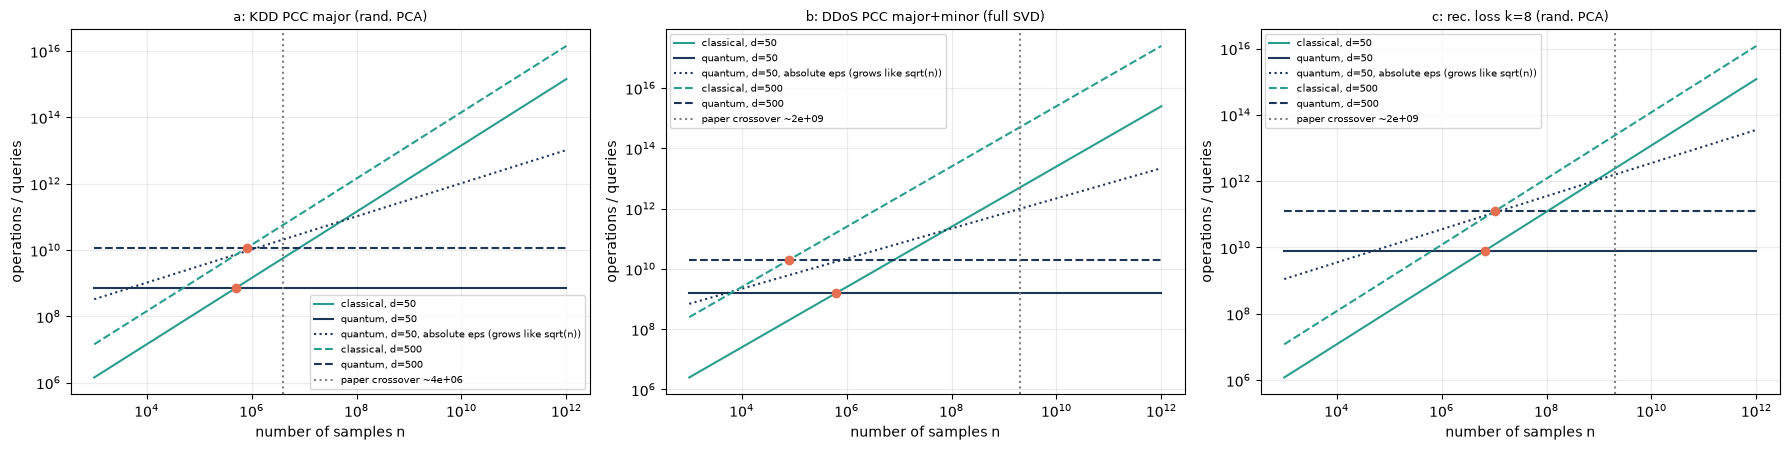

In [18]:
def crossover_n(Q_total, d, k, classical):
    return Q_total / (d * k * L2(k)) if classical == "rand" else Q_total / (d * d)               # relative-error scaling: quantum cost independent of n
def crossover_abs(Q_total, d, k, classical, n0):
    c = d * k * L2(k) if classical == "rand" else d * d                                           # absolute eps: quantum cost grows like sqrt(n/n0)
    return (Q_total / c) ** 2 / n0

CASES = {"a: KDD PCC major (rand. PCA)": (P_KDD, "rand", False), "b: DDoS PCC major+minor (full SVD)": (P_DD, "svd", True),
         f"c: rec. loss k={K_RL} (rand. PCA)": (P_RL, "rand", False), "c': rec. loss k=12 (rand. PCA)": (P_RL12, "rand", False), "c'': rec. loss k=32 (rand. PCA)": (P_RL32, "rand", False)}
rows = []
for nm, (P, kind, minor) in CASES.items():
    row = {"case": nm}
    for d in (50, 100, 500):
        Q = q_major(P, d) + (q_minor(P, d) if minor else 0.0)
        row[f"quantum cost d={d}"] = Q
        row[f"crossover n* d={d}"] = crossover_n(Q, d, P["k"], kind)
        row[f"n* (abs. eps) d={d}"] = crossover_abs(Q, d, P["k"], kind, P["n0"])
    rows.append(row)
CROSS = pd.DataFrame(rows).set_index("case")
display(CROSS.map(lambda v: f"{v:.2e}"))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ns = np.logspace(3, 12, 200)
for a_, (nm, (P, kind, minor)), paper_x in zip(ax, list(CASES.items())[:3], (4e6, 2e9, 2e9)):
    for d, ls in ((50, "-"), (500, "--")):
        Q = q_major(P, d) + (q_minor(P, d) if minor else 0.0)
        cl = [c_rand(n, d, P["k"]) if kind == "rand" else c_svd(n, d) for n in ns]
        a_.loglog(ns, cl, ls, color="#2a9d8f", label=f"classical, d={d}"); a_.loglog(ns, [Q] * len(ns), ls, color="#1d3557", label=f"quantum, d={d}")
        a_.plot([crossover_n(Q, d, P["k"], kind)], [Q], "o", color="#e76f51")
        if d == 50: a_.loglog(ns, Q * np.sqrt(ns / P["n0"]), ":", color="#1d3557", label="quantum, d=50, absolute eps (grows like sqrt(n))")
    a_.axvline(paper_x, color="gray", ls=":", label=f"paper crossover ~{paper_x:.0e}")
    a_.set_xlabel("number of samples n"); a_.set_ylabel("operations / queries"); a_.set_title(nm, fontsize=9); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Decision step (Section 5.7): the DDoS-sized training sets

The paper evaluates its KDD cost model on the training set of a large volume attack: 340 million packets in one second (Microsoft, 3.47 Tbit/s) or 130 million (GitHub, 1.35 Tbit/s), with 50 features, and reports
about 1.3e8 quantum operations against 3.9e10 (Microsoft) and 1.4e8 against 1.3e10 (GitHub) classical ones. The same two sizes under this notebook's measured parameters:

In [19]:
rows = []
for nm, n in (("Microsoft 2022, n = 3.4e8", 3.4e8), ("GitHub 2018, n = 1.3e8", 1.3e8)):
    qc, cc = q_major(P_KDD, 50), c_rand(n, 50, P_KDD["k"])
    rows.append({"attack": nm, "quantum (ours)": qc, "classical randomized PCA (ours)": cc, "gap (ours)": cc / qc})
DEC = pd.DataFrame(rows).set_index("attack"); display(DEC.map(lambda v: f"{v:.3g}"))
print("paper: Microsoft 1.3e8 vs 3.9e10 (gap ~300), GitHub 1.4e8 vs 1.3e10 (gap ~90); 'about two orders of magnitude'")

,quantum (ours),classical randomized PCA (ours),gap (ours)
attack,,,
"Microsoft 2022, n = 3.4e8",7.25e+08,4.85e+11,669
"GitHub 2018, n = 1.3e8",7.25e+08,1.85e+11,256


paper: Microsoft 1.3e8 vs 3.9e10 (gap ~300), GitHub 1.4e8 vs 1.3e10 (gap ~90); 'about two orders of magnitude'


## 10. Tomography: how many measurements are really needed? (paper Appendix C, Figures C.6 and C.7)

The theorem asks for `N = 36 d ln(d) / delta^2` measurements to learn a unit vector of length `d` to `l2` error `delta` with high probability. The paper checks on the **first principal component of CIC-MalMem-2022** (`d = 55`)
that about 1e4 measurements already give `delta = 0.03` instead of the 1e7 of the bound (for `delta = 0.03`, `d = 55`: 8.8e6), and that repeating the experiment 1000 times with 20 861 measurements gives errors centred on 0.03.

first principal component of CIC-MalMem-2022: d = 55 | share of variance: 0.3
measurements needed for l2 error 0.03: simulated 13,769  | theorem bound 8,816,133  | saving factor 640   [paper: ~1e4 vs ~1e7 (20 861 used in Fig. C.7), saving up to ~1e3]
analytic expectation sqrt((d-1)/(4N)) = 0.0313 at the simulated N (should be ~0.03)
1000 repetitions with N = 13,769: error mean 0.0306, median 0.0305, std 0.0031


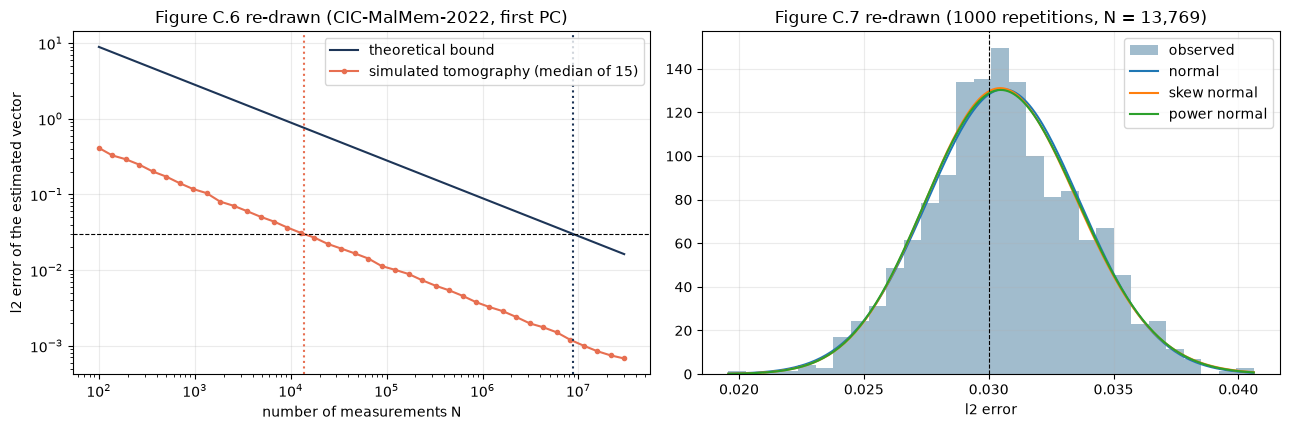

In [20]:
rs = np.random.default_rng(SEED + 9)
mal_scale = np.where(mal_X.std(0) > 0, mal_X.std(0), 1.0)
mal_Zf = (mal_X - mal_X.mean(0)) / mal_scale                         # all 55 features kept (constant ones become zero columns)
v_mal = np.linalg.svd(mal_Zf, full_matrices=False)[2][0]
d_m = len(v_mal); print("first principal component of CIC-MalMem-2022: d =", d_m, "| share of variance:", round(float(np.linalg.svd(mal_Zf, compute_uv=False)[0] ** 2 / (mal_Zf ** 2).sum()), 3))

def tomo_error(N, rs):
    counts = rs.multinomial(N, v_mal ** 2 / (v_mal ** 2).sum())
    est = np.sign(v_mal) * np.sqrt(counts / N); est /= np.linalg.norm(est)
    return np.linalg.norm(est - v_mal)

Ns = np.unique(np.geomspace(1e2, 3e7, TOMO_GRID_PTS).astype(int))
med = np.array([np.median([tomo_error(int(N), rs) for _ in range(15)]) for N in Ns])
bound_err = np.sqrt(36 * d_m * np.log(d_m) / Ns)                       # error guaranteed by the theorem for N measurements
DELTA_T = 0.03
N_needed = float(np.exp(np.interp(np.log(DELTA_T), np.log(med[::-1]), np.log(Ns[::-1]))))
N_bound = 36 * d_m * math.log(d_m) / DELTA_T ** 2
print(f"measurements needed for l2 error {DELTA_T}: simulated {N_needed:,.0f}  | theorem bound {N_bound:,.0f}  | saving factor {N_bound/N_needed:,.0f}   [paper: ~1e4 vs ~1e7 (20 861 used in Fig. C.7), saving up to ~1e3]")
print(f"analytic expectation sqrt((d-1)/(4N)) = {math.sqrt((d_m-1)/(4*N_needed)):.4f} at the simulated N (should be ~{DELTA_T})")

N0 = int(round(N_needed))
errs = np.array([tomo_error(N0, rs) for _ in range(TOMO_REPEATS)])
print(f"{TOMO_REPEATS} repetitions with N = {N0:,}: error mean {errs.mean():.4f}, median {np.median(errs):.4f}, std {errs.std():.4f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].loglog(Ns, bound_err, color="#1d3557", label="theoretical bound"); ax[0].loglog(Ns, med, "o-", color="#e76f51", ms=3, label="simulated tomography (median of 15)")
ax[0].axhline(DELTA_T, color="k", ls="--", lw=0.8); ax[0].axvline(N_bound, color="#1d3557", ls=":"); ax[0].axvline(N_needed, color="#e76f51", ls=":")
ax[0].set_xlabel("number of measurements N"); ax[0].set_ylabel("l2 error of the estimated vector"); ax[0].set_title("Figure C.6 re-drawn (CIC-MalMem-2022, first PC)"); ax[0].legend()
ax[1].hist(errs, bins=30, density=True, alpha=0.5, color="#457b9d", label="observed")
xs = np.linspace(errs.min(), errs.max(), 200)
for nm, dist in (("normal", stats.norm), ("skew normal", stats.skewnorm), ("power normal", stats.powernorm)):
    try: ax[1].plot(xs, dist.pdf(xs, *dist.fit(errs)), label=nm)
    except Exception: pass
ax[1].axvline(DELTA_T, color="k", ls="--", lw=0.8); ax[1].set_xlabel("l2 error"); ax[1].set_title(f"Figure C.7 re-drawn ({TOMO_REPEATS} repetitions, N = {N0:,})"); ax[1].legend()
plt.tight_layout(); plt.show()

## 11. Clustering with PCA and q-means (paper Appendix E, Figure E.8)

KDD Cup 99 (all rows of the 10 % file, min-max normalised) is projected on the **first principal component** and clustered in 1-D with `n_k = 10, 20, ..., 100` clusters; the clustering quality is the Calinski-Harabasz (CH) index.
Quantum version: the component comes from the simulated QPCA (`p` = share of the first component, `eps = eps_theta = 5`, `eta = 0.1`, `delta = 0.1`), and the clusters from a q-means simulation with centroid error `delta = 0.0005`
(each Lloyd update is perturbed by `U(-delta, delta)`; the distance-estimation error of Theorem B.10 is not given in the paper and is not simulated; **CHOICE**). In one dimension Lloyd's algorithm only needs sorted data and prefix sums, so it runs in a fraction of a second.

KDD (all rows) first principal component keeps 59.4 % of the variance   [paper: ~60 %]; n = 494,021, d = 36


components selected by the simulated quantum search: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
CH index, classical: [4.03714440e+07 5.24385590e+07 8.73476760e+07 9.51453010e+07
 1.33066741e+08 1.28541965e+08 1.55651747e+08 1.75236629e+08
 1.65662207e+08 1.59337920e+08]
CH index, quantum  : [4.06827530e+07 4.66271260e+07 6.69606180e+07 7.02655610e+07
 1.01335020e+08 9.99180600e+07 1.30583444e+08 1.50023602e+08
 1.49420822e+08 1.45348865e+08]
relative difference quantum vs classical: mean 15.65 %, max 26.15 %   [paper: curves match, CH up to ~5e8]


mean relative CH difference versus the q-means centroid error delta_q (one device): {0.0005: 16.71, 0.0001: 6.53, 2e-05: 4.59, 0.0: 0.87} | std of the projected data: 1.132


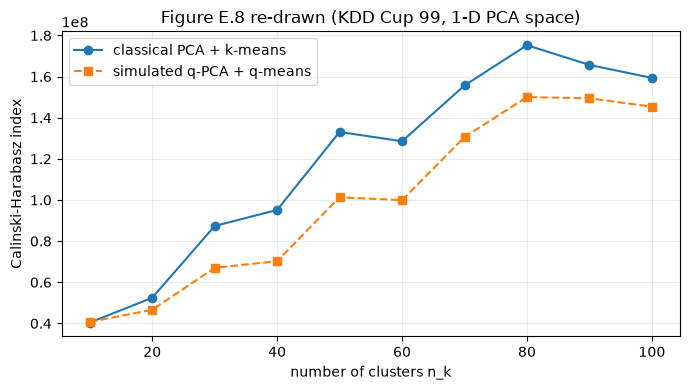

In [21]:
Xe = kdd[KDD_NUM].to_numpy(float)
keep_e = Xe.std(0) > 0
Xe = Xe[:, keep_e]; Xe = (Xe - Xe.min(0)) / (Xe.max(0) - Xe.min(0)); Xe = Xe - Xe.mean(0)      # CHOICE: min-max normalisation; with it (centred) the first PC keeps ~59 % (the paper's ~60 %), standardization gives 22 %
evals, evecs = np.linalg.eigh(Xe.T @ Xe); order = np.argsort(evals)[::-1]
M_e = dict(S=np.sqrt(np.maximum(evals[order], 0)), V=evecs[:, order].T, mean=np.zeros(Xe.shape[1]), n=len(Xe), d=Xe.shape[1])
M_e["lam"] = M_e["S"] ** 2; M_e["ratio"] = M_e["lam"] / M_e["lam"].sum()
p_e = float(M_e["ratio"][0]); print(f"KDD (all rows) first principal component keeps {100*p_e:.1f} % of the variance   [paper: ~60 %]; n = {M_e['n']:,}, d = {M_e['d']}")

def kmeans_1d(xs, csum, nk, rs, noise=0.0, iters=60):
    n = len(xs); c = np.quantile(xs, (np.arange(nk) + 0.5) / nk)           # CHOICE: deterministic quantile initialisation
    for _ in range(iters):
        edges = np.r_[0, np.searchsorted(xs, 0.5 * (c[1:] + c[:-1])), n]
        cnt = np.diff(edges); sums = csum[edges[1:]] - csum[edges[:-1]]
        newc = np.where(cnt > 0, sums / np.maximum(cnt, 1), c)
        if noise: newc = newc + rs.uniform(-noise, noise, size=nk)
        c = np.sort(newc)
    return np.r_[0, np.searchsorted(xs, 0.5 * (c[1:] + c[:-1])), n]

def ch_index(xs, csum, csq, edges):
    n, k = len(xs), len(edges) - 1
    cnt = np.diff(edges); ok = cnt > 0
    sums, sq = csum[edges[1:]] - csum[edges[:-1]], csq[edges[1:]] - csq[edges[:-1]]
    mean_all = csum[-1] / n
    B = (cnt[ok] * (sums[ok] / cnt[ok] - mean_all) ** 2).sum(); W = (sq[ok] - sums[ok] ** 2 / cnt[ok]).sum()
    return (B / (ok.sum() - 1)) / (W / (n - ok.sum()))

def ch_curve(proj, noise, seed):
    xs = np.sort(proj); csum = np.r_[0, np.cumsum(xs)]; csq = np.r_[0, np.cumsum(xs ** 2)]
    rs = np.random.default_rng(seed)
    return [ch_index(xs, csum, csq, kmeans_1d(xs, csum, nk, rs, noise)) for nk in CLUSTER_NK]

proj_c = Xe @ M_e["V"][0]
ch_c = ch_curve(proj_c, 0.0, SEED)
ch_q_all, k_e = [], []
for s in range(N_QSEEDS):
    dev = QDevice(M_e, SEED + 500 + s)
    qc = quantum_components(M_e, dev, p=p_e, eps_theta=Q_E["eps_theta"], eps=Q_E["eps"], eta=Q_E["eta"], delta=Q_E["delta"])
    first = int(np.argmin(qc["idx_major"])); k_e.append(qc["k"])
    ch_q_all.append(ch_curve(Xe @ qc["major"][0][first], Q_E["delta_qmeans"], SEED + 600 + s))
ch_q = np.mean(ch_q_all, 0); rel = np.abs(ch_q - ch_c) / ch_c
print("components selected by the simulated quantum search:", k_e)
print("CH index, classical:", np.array(ch_c).round(0)); print("CH index, quantum  :", ch_q.round(0))
print(f"relative difference quantum vs classical: mean {100*rel.mean():.2f} %, max {100*rel.max():.2f} %   [paper: curves match, CH up to ~5e8]")
# sensitivity to the q-means centroid error (the paper's 0.0005 is given without the scale of the data)
sw = []
for dq in (Q_E["delta_qmeans"], 1e-4, 2e-5, 0.0):
    dev = QDevice(M_e, SEED + 500); qc = quantum_components(M_e, dev, p=p_e, eps_theta=Q_E["eps_theta"], eps=Q_E["eps"], eta=Q_E["eta"], delta=Q_E["delta"])
    cq = np.array(ch_curve(Xe @ qc["major"][0][int(np.argmin(qc["idx_major"]))], dq, SEED + 600))
    sw.append((dq, round(100 * float(np.mean(np.abs(cq - np.array(ch_c)) / np.array(ch_c))), 2)))
print("mean relative CH difference versus the q-means centroid error delta_q (one device):", dict(sw), "| std of the projected data:", round(float((Xe @ M_e["V"][0]).std()), 3))
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(CLUSTER_NK, ch_c, "o-", label="classical PCA + k-means"); ax.plot(CLUSTER_NK, ch_q, "s--", label="simulated q-PCA + q-means")
ax.set_xlabel("number of clusters n_k"); ax.set_ylabel("Calinski-Harabasz index"); ax.set_title("Figure E.8 re-drawn (KDD Cup 99, 1-D PCA space)"); ax.legend(); plt.tight_layout(); plt.show()

## 12. Resource estimation of the QRAM (paper Section 5.8)

Step 4 of the methodology. The data structure for `n = 1e7` rows and `d = 44` features has `O(n*d*log(nd))` nodes; with a 1-bit word its address needs `ceil(log2(n*d*log2(n*d)))` bits. The logical-qubit, T-gate, Clifford-gate and depth numbers of the paper come from the external circuit
generator of Di Matteo et al. and the surface-code estimates from their hardware model; **this notebook cannot rerun those tools**. It re-computes the address width, checks the paper's quoted figures for internal consistency, and redoes the time-ratio argument of the paper.

In [22]:
n_q, d_q = 1e7, 44
bits = math.ceil(math.log2(n_q * d_q * math.log2(n_q * d_q)))
print(f"address bits = ceil(log2(n d log2(n d))) = {bits}   [paper: 34]")
PAPER_Q = {"logical qubits": 1.37e11, "T gates": 3.61e11, "Clifford gates": 9.28e11, "circuit depth": 539, "T depth": 67}
# observation (not a derivation): the quoted figures are small integer multiples of 2^bits, or linear in bits
FIT = {"logical qubits": 8 * 2 ** bits, "T gates": 21 * 2 ** bits, "Clifford gates": 54 * 2 ** bits, "circuit depth": 16 * bits - 5, "T depth": 2 * bits - 1}
print("consistency of the paper's quoted figures with 'integer multiples of 2^34 / linear in 34' (single data point, fitted by us):")
display(pd.DataFrame({"paper": PAPER_Q, "simple formula": FIT, "ratio": {k: PAPER_Q[k] / FIT[k] for k in FIT}}).T.map(lambda v: f"{v:.4g}"))
for lab, phys, t_q in (("optimistic hardware (1e-5 gate error, 200 ns cycle)", 2.08e14, 1.07e-3), ("less optimistic (1e-3, 1 us)", 7.31e16, 28.1e-3)):
    print(f"{lab}: {phys:.3g} physical qubits = {phys/PAPER_Q['logical qubits']:.0f} per logical qubit; one QRAM query {t_q*1e3:.2f} ms = {t_q/1e-9:.2g} x a 1 ns classical RAM access")
t_quantum = 1.3e8 * 1.07e-3; t_classical = 3.9e10 * 1e-9
print(f"paper's own operation counts (1.3e8 quantum QRAM queries vs 3.9e10 classical steps): {t_quantum/3600:.1f} h of QRAM time versus {t_classical:.0f} s of classical time with 1 ns per step")

address bits = ceil(log2(n d log2(n d))) = 34   [paper: 34]
consistency of the paper's quoted figures with 'integer multiples of 2^34 / linear in 34' (single data point, fitted by us):


,logical qubits,T gates,Clifford gates,circuit depth,T depth
paper,1.37e+11,3.61e+11,9.28e+11,539,67
simple formula,1.374e+11,3.608e+11,9.277e+11,539,67
ratio,0.9968,1.001,1,1,1


optimistic hardware (1e-5 gate error, 200 ns cycle): 2.08e+14 physical qubits = 1518 per logical qubit; one QRAM query 1.07 ms = 1.1e+06 x a 1 ns classical RAM access
less optimistic (1e-3, 1 us): 7.31e+16 physical qubits = 533577 per logical qubit; one QRAM query 28.10 ms = 2.8e+07 x a 1 ns classical RAM access
paper's own operation counts (1.3e8 quantum QRAM queries vs 3.9e10 classical steps): 38.6 h of QRAM time versus 39 s of classical time with 1 ns per step


## 13. Side-by-side comparison with the paper, claim by claim

In [23]:
def share_ok(df, a, b):
    return float(np.mean(np.concatenate([(df[(m, a)] - df[(m, b)]).abs().to_numpy() <= TOL_PTS for m in PAPER_METRICS])))
def verdict_share(s, thr=0.75): return "reproduced" if s >= thr else "not reached"
w3, w7 = within(T3), within(C7)
s4_1, s4_2 = share_ok(T4, "paper q1", "ours q1"), share_ok(T4, "paper q2", "ours q2")
gap3 = float((q3[PAPER_METRICS] - c3[PAPER_METRICS]).abs().max().max()); gap7 = float((q7[PAPER_METRICS] - c7[PAPER_METRICS]).abs().max().max())
gap_f1_pcc, gap_f1_ens = float((q1["F1"] - c_pcc["F1"]).abs().max()), float((q2["F1"] - c_ens["F1"]).abs().max())
ens_gain = bool((q2["F1"].loc[2:] > q1["F1"].loc[2:]).all())
sh5 = float(np.mean([abs(T5w.loc[x, m] - PAPER_T5.loc[x, m]) <= TOL_PTS for x in (0.01, 0.1, 0.9, 2.0) for m in PAPER_METRICS]))
gap5 = abs(T5.loc[0.01, "F1"] - T5.loc["classical", "F1"])
def bracket(paper_n, case, d):
    lo, hi = sorted((CROSS.loc[case, f"crossover n* d={d}"], CROSS.loc[case, f"n* (abs. eps) d={d}"]))
    txt = f"n* in [{lo:.2g}, {hi:.2g}] (relative / absolute eps)"
    if lo <= paper_n <= hi: return txt, "reproduced (paper value inside the bracket)"
    if lo / 10 <= paper_n <= hi * 10: return txt, "reproduced (within x10 of the bracket)"
    return txt, "not reached"
CASE_A, CASE_B, CASE_C = "a: KDD PCC major (rand. PCA)", "b: DDoS PCC major+minor (full SVD)", f"c: rec. loss k={K_RL} (rand. PCA)"
txt_a, v_a = bracket(4e6, CASE_A, 50); txt_b, v_b = bracket(2e9, CASE_B, 100); txt_c, v_c = bracket(2e9, CASE_C, 50)
Q_b500 = q_major(P_DD, 500) + q_minor(P_DD, 500)
no_adv_rel, no_adv_abs = Q_b500 > c_svd(3e7, 500), Q_b500 * math.sqrt(3e7 / P_DD["n0"]) > c_svd(3e7, 500)
gap_ours, gap_paper = DEC.iloc[0, 2], 3.9e10 / 1.3e8
claims = [
 ("Table 3: classical PCA70 and QPCA70 numbers on KDD (recall, precision, F1, accuracy)", "e.g. alpha=1%: recall 93.14, precision 98.63, F1 95.81, acc 97.55",
  f"alpha=1%: recall {c3.loc[1,'Recall']:.2f}, precision {c3.loc[1,'Precision']:.2f}, F1 {c3.loc[1,'F1']:.2f}, acc {c3.loc[1,'Accuracy']:.2f}; cells within 2 pts: classical {w3['c']:.2f}, quantum {w3['q']:.2f}", verdict_share(min(w3['c'], w3['q']))),
 ("Table 3: QPCA matches classical PCA with eps=1, eta=0.1, delta=0.1", "max gap 0.4 pt (precision 1.99 at alpha=6)", f"max gap quantum vs classical {gap3:.2f} pt", "reproduced" if gap3 <= TOL_PTS else "not reached"),
 ("Table C.7: major + minor components on KDD", "alpha=1%: recall 98.62, precision 97.26, F1 97.94", f"alpha=1%: recall {c7.loc[1,'Recall']:.2f}, precision {c7.loc[1,'Precision']:.2f}, F1 {c7.loc[1,'F1']:.2f}; cells within 2 pts: classical {w7['c']:.2f}, quantum {w7['q']:.2f}; max q-c gap {gap7:.2f} pt", verdict_share(min(w7['c'], w7['q']))),
 ("Table 4: PCC (major+minor) on CIC-IDS2017 DDoS is poor", "F1 52.6 / 75.8 / 75.0 at alpha=1 / 4 / 10", f"F1 {q1.loc[1,'F1']:.1f} / {q1.loc[4,'F1']:.1f} / {q1.loc[10,'F1']:.1f}; cells within 2 pts {s4_1:.2f}", verdict_share(s4_1)),
 ("Table 4: Ensemble PCC clearly improves on PCC (F1, recall)", "F1 gain at alpha=4: +14.4 pt", f"Ensemble F1 above PCC for alpha>=2: {ens_gain}; gain at alpha=4: {q2.loc[4,'F1']-q1.loc[4,'F1']:+.1f} pt; Ensemble cells within 2 pts {s4_2:.2f}", "reproduced" if ens_gain else "not reached"),
 ("Table 4: quantum equals classical for both detectors", "'matches the classical equivalent'", f"max F1 gap quantum vs classical: PCC {gap_f1_pcc:.2f} pt, Ensemble {gap_f1_ens:.2f} pt", "reproduced" if max(gap_f1_pcc, gap_f1_ens) <= TOL_PTS else "not reached"),
 ("Table 5: delta=0.01 equals classical reconstruction-loss PCA", "F1 95.04 = 95.04", f"F1 gap {gap5:.2f} pt (classical F1 {T5.loc['classical','F1']:.2f}, stated test set)", "reproduced" if gap5 <= TOL_PTS else "not reached"),
 ("Table 5: larger delta -> recall up, precision down", "delta 0.9: 99.79 / 71.31; delta 2: 100 / 27.30", f"monotone trend: {mono(T5)}; delta=2 (re-weighted): recall {T5w.loc[2.0,'Recall']:.1f}, precision {T5w.loc[2.0,'Precision']:.1f}", "reproduced" if mono(T5) else "not reached"),
 ("Table 5: absolute numbers (classical 99.12 / 91.28 / 95.04 / 98.08)", "recall/precision/F1/accuracy", f"re-weighted to the implied attack share: cells within 2 pts {sh5:.2f}; stated composition: {T5.loc['classical'].round(1).tolist()}", verdict_share(sh5)),
 ("Table 5: stated test set (140 000 normal + 389 590 attacks) is consistent with the table", "accuracy 98.08 with recall 99.12 / precision 91.28", f"implied attack share {100*share_implied:.1f} % versus stated {100*RL_N_TEST_ATTACK/(RL_N_TEST_ATTACK+RL_N_TEST_NORMAL):.1f} %", "not reached (internal inconsistency of the paper)"),
 ("Table 6 and Figure 5 (DARKNET)", "recall 84.4/84.17, precision 73.18/73.71", "dataset not publicly downloadable", "cannot be checked"),
 ("Figure 4a: PCC-major on KDD, advantage after ~4e6 samples at ~50 features", "n* ~ 4e6", txt_a, v_a),
 ("Figure 4b: major+minor with full SVD, advantage after ~2e9 samples at ~100 features", "n* ~ 2e9", txt_b, v_b),
 ("Figure 4b text: no advantage at 3e7 samples x 500 features", "quantum slower", f"quantum cost {Q_b500:.2g} (relative eps) / {Q_b500*math.sqrt(3e7/P_DD['n0']):.2g} (absolute eps) vs classical SVD {c_svd(3e7,500):.2g}", "reproduced (absolute-eps scaling)" if (no_adv_abs and not no_adv_rel) else ("reproduced" if no_adv_rel else "not reached")),
 ("Figure 4c: reconstruction loss, advantage after ~2e9 samples", "n* ~ 2e9", txt_c, v_c),
 ("Section 5.7: Microsoft-size attack, ~1.3e8 quantum vs ~3.9e10 classical operations (gap ~300)", "1.3e8 vs 3.9e10", f"{DEC.iloc[0,0]:.2g} vs {DEC.iloc[0,1]:.2g} (gap {gap_ours:.0f}); the paper's classical count implies k*log2(k) = {3.9e10/(3.4e8*50):.1f}", "reproduced (gap within x10)" if 0.1 <= gap_ours / gap_paper <= 10 else "not reached"),
 ("Appendix C: ~1e4 measurements instead of ~1e7 give l2 error 0.03 (CIC-MalMem-2022, d=55)", "20 861 needed, bound 8.8e6", f"{N_needed:,.0f} needed, bound {N_bound:,.0f} (saving x{N_bound/N_needed:,.0f})", "reproduced" if 0.5 <= N_needed / 20861 <= 2 else "not reached"),
 ("Figure C.7: errors centred at 0.03 for N=20 861", "centre ~0.03", f"mean error {errs.mean():.4f} at N={N0:,}", "reproduced" if abs(errs.mean() - 0.03) < 0.005 else "not reached"),
 ("Appendix E: q-means + QPCA matches classical CH index", "curves coincide", f"mean relative difference {100*rel.mean():.2f} %", "reproduced" if rel.mean() < 0.05 else "not reached"),
 ("Section 5.8: 34 address bits; 1.37e11 logical qubits, 539 layers, T 3.61e11, T-depth 67, Clifford 9.28e11", "as quoted", f"34 bits: {bits == 34}; quoted figures are consistent with integer multiples of 2^34 (see table)", "reproduced (arithmetic only)"),
 ("Section 5.8: 2.08e14 / 7.31e16 physical qubits, 1.07 ms / 28.1 ms per QRAM query", "as quoted", "needs the external Di Matteo et al. estimator", "cannot be checked"),
]
CLAIMS = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
with pd.option_context("display.max_colwidth", 140, "display.width", 260): display(CLAIMS)
print(CLAIMS["verdict"].str.split(" ").str[0].value_counts().to_dict())

,claim,paper,this notebook,verdict
0,"Table 3: classical PCA70 and QPCA70 numbers on KDD (recall, precision, F1, accuracy)","e.g. alpha=1%: recall 93.14, precision 98.63, F1 95.81, acc 97.55","alpha=1%: recall 93.65, precision 96.71, F1 95.16, acc 97.13; cells within 2 pts: classical 0.46, quantum 0.46",not reached
1,"Table 3: QPCA matches classical PCA with eps=1, eta=0.1, delta=0.1",max gap 0.4 pt (precision 1.99 at alpha=6),max gap quantum vs classical 1.27 pt,reproduced
2,Table C.7: major + minor components on KDD,"alpha=1%: recall 98.62, precision 97.26, F1 97.94","alpha=1%: recall 98.85, precision 95.75, F1 97.27; cells within 2 pts: classical 0.50, quantum 0.50; max q-c gap 0.20 pt",not reached
3,Table 4: PCC (major+minor) on CIC-IDS2017 DDoS is poor,F1 52.6 / 75.8 / 75.0 at alpha=1 / 4 / 10,F1 37.4 / 66.3 / 75.3; cells within 2 pts 0.21,not reached
4,"Table 4: Ensemble PCC clearly improves on PCC (F1, recall)",F1 gain at alpha=4: +14.4 pt,Ensemble F1 above PCC for alpha>=2: True; gain at alpha=4: +10.7 pt; Ensemble cells within 2 pts 0.04,reproduced
5,Table 4: quantum equals classical for both detectors,'matches the classical equivalent',"max F1 gap quantum vs classical: PCC 9.31 pt, Ensemble 11.82 pt",not reached
6,Table 5: delta=0.01 equals classical reconstruction-loss PCA,F1 95.04 = 95.04,"F1 gap 0.03 pt (classical F1 92.55, stated test set)",reproduced
7,"Table 5: larger delta -> recall up, precision down",delta 0.9: 99.79 / 71.31; delta 2: 100 / 27.30,"monotone trend: True; delta=2 (re-weighted): recall 100.0, precision 18.6",reproduced
8,Table 5: absolute numbers (classical 99.12 / 91.28 / 95.04 / 98.08),recall/precision/F1/accuracy,"re-weighted to the implied attack share: cells within 2 pts 0.25; stated composition: [97.5, 88.1, 92.6, 88.5]",not reached
9,Table 5: stated test set (140 000 normal + 389 590 attacks) is consistent with the table,accuracy 98.08 with recall 99.12 / precision 91.28,implied attack share 18.6 % versus stated 73.6 %,not reached (internal inconsistency of the paper)


{'reproduced': 10, 'not': 9, 'cannot': 2}


## 14. Reading the paper critically

* **A scoping paper, not a performance paper.** The authors state that the case study is not meant to beat the state of the art; the conclusion that matters is "the advantage appears only for very large `n`" and that conclusion rests on running-time formulas with the `O~` constants removed. Changing the logarithm base or the hidden constants moves the crossover by an order of magnitude, so the tolerance used in section 13 for the crossover claims is a factor of 10, not 2 points.
* **How the data grow is a modelling choice.** The quantum cost depends on `|X|/theta` and `mu(X)/eps`. If `eps` is an *absolute* error on the singular values of the unnormalised matrix, these ratios grow like `sqrt(n)` and the "polylogarithmic in `n`" advantage disappears; the paper's plots implicitly keep the relative error fixed. The authors do not say so, and their simulation code is not reproduced in the article.
* **Internal inconsistencies.** (i) The text of section 5.5 first reports 12 components (94.88 % of the variance) and later 32 components (99.75 %) for the same model; (ii) the stated Table 5 test set (140 000 normal, 389 590 attacks, 73.6 % attacks) cannot produce the table's accuracy (98.08 %) together with its recall and precision; they imply an attack share near 18.6 %, so either the sizes or the table come from a different split (section 7 reports both); (iii) Section 5.5 mentions 6 components for 70 % of the variance on KDD while Appendix D uses 10.
* **Threshold calibration.** The paper's precision falls much more slowly with the false-alarm rate `alpha` than the nominal `alpha` suggests (its Table 3 implies a false-positive rate of about `alpha/2` on the test normals); with the recipe used here (quantile of the training scores) the false-alarm rate on unseen normals is larger, which is why our precision at large `alpha` is lower than the paper's while the recall agrees.
* **Error model.** Uniform phase-estimation errors, a bisection with uniform amplitude-estimation noise, and perturbation-by-`delta` tomography are reasonable but not unique; `delta = 0.9` or `2` is not a tomography error that a real estimator could produce for unit vectors (the maximum possible distance is 2), it is an adversarially large perturbation used to show the trend.
* **PCA detectors are weak.** Table 4 shows that the plain PCC loses to the authors' own ensemble by 15 F1 points; the labelled Random Forest and SVC reference in sections 5 and 6 shows how much a supervised model, which sees attacks, improves on any of these unsupervised detectors on the same features.
* **Quantum versus classical in Table 4.** In this notebook the quantum Ensemble PCC does not match its classical twin as closely as the paper reports: most of the gap closes when the binary-search error `eta` is small enough to select the same `k` as the classical model (table after Table 4), the rest comes from minor components whose singular values are below the phase-estimation resolution `eps`.
* **The classical operation counts of Section 5.7.** 3.9e10 operations for 3.4e8 packets and 50 features correspond to `n*d*k*log2(k)` with `k*log2(k)` of about 2.3 (k near 2), not to the 9 to 10 components of the models in Section 5.3; with the model's own `k` the classical count is about 12 times larger and the quantum/classical gap correspondingly larger.
* **What the paper does not do.** It does not consider data loading beyond a QRAM resource count, does not simulate noise from hardware, and ignores the cost of the classical pre- and post-processing that the authors themselves say can dominate.

## 15. Exercises

1. Change `Q_KDD["eps"]` from 1 to 10, 30 and 100 and re-run section 5. At which value does `QPCA70` stop matching the classical detector? Express `eps` relative to the smallest kept singular value.
2. Replace the uniform phase-estimation error by the *worst case* `sigma_est = sigma + eps*sign` with random signs. How many components does the bisection find? Does the tolerance on `eta` (try 0.01 and 0.3) matter more than `eps`?
3. In `crossover_n`, make `eps` an absolute quantity that does not scale with `sqrt(n)`: multiply `mu_over_eps` by `sqrt(n / n0)`. Plot the new quantum curve against the classical one. Is there still a crossover?
4. Add the Mahalanobis-trimming fraction `TRIM_FRAC` = 0, 0.05 and 0.1 to the KDD experiment. How sensitive are Table 3 and the measured `mu(X)` to a handful of outliers?
5. Download the Darknet CSV yourself (see section 8), build the 50 000 / 30 000 / 35 000 split and add Table 6 to section 13. Does the model need `eta = 0.0011` and 35 components to match the classical model?

In [24]:
print(f"total notebook run time: {(time.time() - T0)/60:.1f} min  (FAST_MODE = {FAST_MODE})")
if CLEAN_BIG_FILES:                       # cached data are large: delete files above 50 MB (they are re-downloaded on the next run)
    for root, _, files in os.walk(DATA_DIR):
        for f in files:
            p = os.path.join(root, f)
            if os.path.getsize(p) > 50 * 2 ** 20:
                os.remove(p); print("removed cached file", p)

total notebook run time: 12.1 min  (FAST_MODE = False)
removed cached file data\cic2017_all_attacks_42_0.16.parquet
